# Phishing URL classifier for analyst triage

This notebook tests whether the URL string alone can rank URLs for analyst review, against two simple rules. Data: PhishVN (Nguyen Vu, 2026). Run from `project/` with *Restart and run all*. Test labels are not used before Section 8.

## 0. Executive summary

- **Question.** Can URL strings alone rank incoming URLs for analyst review?
- **Model.** Calibrated logistic regression on four URL counts and the top-level domain; threshold 0.22, from development data.
- **Against today's rule.** No current rule is documented, so no gain over it is claimed. The test cost is 7,852 EUR per 1,000 URLs, against 11,242 for always answering benign (illustrative prices).
- **Action.** Order review by score; do not block automatically or use on `.vn` traffic yet.
- **Main limit.** The test set was not untouched (Section 8). Recall is 35 % on recent phishing; no test `.vn` phishing URL is caught.

**What this means for the stakeholder.** The score orders a review queue and does not block anything. On test data it catches about one phishing URL in three (35 % recall), so existing controls must stay in place.


## Setup

In [1]:
import warnings, time, json, hashlib, math
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import sklearn
import plotly
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
# matplotlib is the only plotting package beyond the course environment: it draws the static PNG copies of the charts, which GitHub displays (listed in requirements.txt).
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from ast import literal_eval
from IPython.display import Image, display
from scipy import stats
from sklearn.model_selection import GroupKFold, GridSearchCV, StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning

import url_features as uf

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pio.renderers.default = "notebook_connected"
SEED = 42
np.random.seed(SEED)
T0 = time.time()

ROOT = Path.cwd()
assert ROOT.name == "project", "Run the notebook from the project/ folder"
DATA = Path("data/dataset_url.csv")
assert DATA.exists(), "Dataset not found at data/dataset_url.csv"
assert Path("url_features.py").exists() and Path("psl/public_suffix_list.dat").exists()
STATIC = Path("figures")
STATIC.mkdir(exist_ok=True)

def save_static(fig_mpl, name):
    # Static PNG copy of a chart. The Plotly figure stays interactive; the PNG is what GitHub displays.
    path = STATIC / name
    fig_mpl.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig_mpl)
    display(Image(filename=str(path), width=850))

# Illustrative cost assumptions (not measured costs of any organisation)
COST = {"FP": 30.0, "FN": 100.0, "TP": 5.0, "TN": 0.0}
THRESH = np.round(np.arange(0.01, 1.00, 0.01), 2)
INPUTS_A = ["url_len", "num_dots", "num_subdomains", "has_at"]   # Model A
INPUTS_B = INPUTS_A + ["tld"]                                    # Model B
CONFIGS = {"LR-A": ("lr", False), "LR-B": ("lr", True), "HGB-A": ("hgb", False), "HGB-B": ("hgb", True)}
GRIDS = {"lr": {"model__C": [0.01, 0.1, 1.0, 10.0]},
         "hgb": {"model__max_depth": [2, 3, 4], "model__learning_rate": [0.05, 0.1]}}
CAL_METHODS = ["sigmoid", "isotonic"]
CUTOFF_PRIMARY = pd.Timestamp("2021-12-31")
CUTOFF_SENS = pd.Timestamp("2020-12-31")
PRIMARY = "T1 primary: phishing dates, cutoff 2021-12-31"
R_NAME = "R reference: 5 random grouped folds"
print(f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"plotly {plotly.__version__} | matplotlib {matplotlib.__version__} | joblib {joblib.__version__} | seed {SEED}")

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3 | plotly 7.1.0 | matplotlib 3.11.2 | joblib 1.6.0 | seed 42


## 1. From the brief to an ML task

| Element | Definition |
|---|---|
| Decision | Which received URLs go to analyst review first. |
| Task and label | Binary: `phishing` = 1 when a Vietnamese anti-fraud feed lists the domain; `benign` = 0. |
| Grain and moment | One URL, when received; only the URL string is used. |
| Inputs | Model A: four URL features. Model B: A plus `tld`. |
| Today's rule | Not documented (Section 5); naive baselines: majority class, `has_at = 1`. |
| Metric | Expected cost per 1,000 URLs (illustrative prices), with precision and recall. |
| Business translation | Analyst time on false alarms against missed phishing. |

**What changed since the brief, and why.** Hypotheses, KPIs and label are kept. Validation uses phishing first-seen dates (temporal split); bronze is excluded as community-labelled and partly dated. The Tranco join is not run.

**What this means for the stakeholder.** The model ranks URLs for a person to review; it does not block them. Whether it works on the organisation's traffic cannot be shown from these labelled sources.

## 2. Data and quality

PhishVN (Nguyen Vu, 2026; version 4): 53,116 URLs, 29 columns. The benchmark is the gold and silver tiers (18,997 rows); bronze (34,119 rows) is described only. Development uses the official train and validation files.

**Cleaning.** Nothing is dropped and there are no duplicates. Placeholder columns (`text`, `msg_len`, `gen_model`, `has_url`; 100 % empty) are unused, and no nulls are filled. Outliers are kept: 109 development URLs exceed the upper fence of 36 characters (maximum 70).

In [2]:
# Development rows come from the official train and validation files (labels included).
# The test file is not opened in this section; it is read once, in Section 8.
TRAIN = pd.read_csv("data/splits/url_train.csv", dtype=str, keep_default_na=False)
VAL = pd.read_csv("data/splits/url_val.csv", dtype=str, keep_default_na=False)
assert set(TRAIN["split"]) == {"train"} and set(VAL["split"]) == {"val"}
dev_part = pd.concat([TRAIN, VAL], ignore_index=True)
del TRAIN, VAL
assert len(dev_part) == 44175
dev_part["dt"] = pd.to_datetime(dev_part["collected_at"].str.strip(), errors="coerce", dayfirst=True, format="mixed")
dev_part["y"] = (dev_part["label"] == "phishing").astype(int)
dev = dev_part[dev_part["tier"].isin(["gold", "silver"])].reset_index(drop=True).copy()   # benchmark, development only
assert len(dev) == 14665 and int(dev["y"].sum()) == 2100

# Dataset-level descriptive checks: all rows, but the label column is never loaded and no
# model input is derived from this table. Used for data quality only.
HEADER = list(pd.read_csv(DATA, nrows=0).columns)
assert len(HEADER) == 29 and "label" in HEADER
desc = pd.read_csv(DATA, dtype=str, keep_default_na=False, usecols=[c for c in HEADER if c != "label"])
assert desc.shape == (53116, 28)
desc["dt"] = pd.to_datetime(desc["collected_at"].str.strip(), errors="coerce", dayfirst=True, format="mixed")

print("Rows by tier and split (counts only; no labels):")
display(pd.crosstab(desc["tier"], desc["split"], margins=True))
print("Bronze development labels (descriptive only):",
      dev_part.loc[dev_part["tier"] == "bronze", "label"].value_counts().to_dict())

Rows by tier and split (counts only; no labels):


split,test,train,val,All
tier,,,,
bronze,4609,23829,5681,34119
gold,2673,6640,280,9593
silver,1659,6440,1305,9404
All,8941,36909,7266,53116


Bronze development labels (descriptive only): {'phishing': 29510}


In [3]:
MISSING = {"", "na", "n/a", "null", "none", "nan"}
cols_missing = ["url", "text", "msg_len", "gen_model", "has_url", "impersonated_org", "status", "rank", "collected_at"]
rows_miss = []
for c in cols_missing:
    m = desc[c].str.strip().str.lower().isin(MISSING)
    rows_miss.append([c, int(m.sum()), round(100 * m.mean(), 1)])
miss = pd.DataFrame(rows_miss, columns=["column", "rows empty or placeholder", "% of rows"])
display(miss)
assert int(desc["url"].str.strip().isin(MISSING).sum()) == 0
assert int(desc["text"].str.strip().isin(MISSING).sum()) == len(desc)
assert int(desc["collected_at"].str.strip().isin(MISSING).sum()) == 31455

NUMERIC = ["url_len", "num_dots", "num_subdomains", "has_ip", "has_at"]
for c in NUMERIC:
    assert pd.to_numeric(desc[c], errors="coerce").notna().all(), c
print("Numeric columns parse without error:", NUMERIC)

n_dup_exact = int(desc["url"].str.strip().duplicated().sum())
n_dup_norm = int(desc["url_norm"].str.strip().str.lower().duplicated().sum())
print(f"Exact duplicate URLs: {n_dup_exact}. Duplicates after lower-casing url_norm: {n_dup_norm}.")
assert n_dup_exact == 0
print("Rows removed by the cleaning steps in this notebook: 0 (nothing is dropped; see outliers below).")

has_date = desc["collected_at"].str.strip() != ""
dates = desc["collected_at"].str.strip()
iso = dates.str.contains("^[0-9]{4}-[0-9]{2}-[0-9]{2}", regex=True)
dmy = dates.str.contains("^[0-9]{2}/[0-9]{2}/[0-9]{4}$", regex=True)
print(f"Non-empty collected_at: {int(has_date.sum())}; ISO format: {int(iso.sum())}; "
      f"day/month/year format: {int(dmy.sum())}; unparsed: {int((has_date & desc['dt'].isna()).sum())}")
assert int((has_date & desc["dt"].isna()).sum()) == 0
assert int(iso.sum()) + int(dmy.sum()) == int(has_date.sum())

,column,rows empty or placeholder,% of rows
0,url,0,0.0
1,text,53116,100.0
2,msg_len,53116,100.0
3,gen_model,53116,100.0
4,has_url,53116,100.0
5,impersonated_org,51090,96.2
6,status,50529,95.1
7,rank,44611,84.0
8,collected_at,31455,59.2


Numeric columns parse without error: ['url_len', 'num_dots', 'num_subdomains', 'has_ip', 'has_at']
Exact duplicate URLs: 0. Duplicates after lower-casing url_norm: 0.
Rows removed by the cleaning steps in this notebook: 0 (nothing is dropped; see outliers below).


Non-empty collected_at: 21661; ISO format: 17048; day/month/year format: 4613; unparsed: 0


In [4]:
snap = pd.to_datetime(desc["scraped_at"].str.strip(), utc=True, errors="coerce")
print("Latest scraped_at (collection snapshot):", snap.max())
tl = desc.groupby(["tier", "source"]).agg(rows=("url", "size"), dated=("dt", lambda s: int(s.notna().sum())),
                                          first_date=("dt", "min"), last_date=("dt", "max"))
display(tl)
ncsc_last = desc.loc[desc["source"] == "tinnhiemmang", "dt"].max()
print("Last dated record of the NCSC feed (source tinnhiemmang):", ncsc_last.date())
assert ncsc_last == pd.Timestamp("2025-02-18")
gap_days = (snap.max().tz_localize(None) - ncsc_last).days
print(f"Days between the last NCSC date and the collection snapshot: {gap_days}")

comp = desc[desc["tier"].isin(["gold", "silver"])].groupby(["tier", "source"]).size().rename("rows").to_frame()
print("Benchmark composition by tier and source (no labels):")
display(comp)

Latest scraped_at (collection snapshot): 2026-07-16 11:03:47.088027+00:00


rows  dated first_date  last_date
tier   source                                          
bronze chongluadao   33823  17048 2021-01-06 2024-05-16
       openphish       296      0        NaT        NaT
gold   tinnhiem_org   2026   2026 2021-04-01 2026-03-25
       tinnhiem_web   5879      0        NaT        NaT
       tinnhiemmang   1688   1688 2020-02-08 2025-01-15
silver tinnhiemmang    899    899 2021-05-27 2025-02-18
       tranco         5993      0        NaT        NaT
       tranco_vn      2512      0        NaT        NaT

Last dated record of the NCSC feed (source tinnhiemmang): 2025-02-18
Days between the last NCSC date and the collection snapshot: 513
Benchmark composition by tier and source (no labels):


rows
tier   source            
gold   tinnhiem_org  2026
       tinnhiem_web  5879
       tinnhiemmang  1688
silver tinnhiemmang   899
       tranco        5993
       tranco_vn     2512

In [5]:
feat = uf.features_frame(dev["url"])
dev = pd.concat([dev.reset_index(drop=True), feat.add_prefix("f_")], axis=1)
dev["grp"] = dev["f_registrable_full"]              # grouping key: registrable domain (full PSL)
assert dev[["f_url_len", "f_num_dots", "f_num_subdomains", "f_has_at"]].notna().all().all()

host_dev = dev["url"].map(uf._host)
shared = dev.assign(h=host_dev).groupby("h").agg(urls=("url", "size"), labels=("y", "nunique"))
shared = shared[shared["urls"] > 1]
print(f"Development hosts shared by more than one URL (user-info removed): {len(shared)} hosts, "
      f"{int(shared['urls'].sum())} URLs; hosts whose URLs carry both labels: {int((shared['labels'] > 1).sum())}")

rows_out = []
for c in ["f_url_len", "f_num_dots", "f_num_subdomains"]:
    q1, q3 = dev[c].quantile([0.25, 0.75])
    up = q3 + 1.5 * (q3 - q1)
    rows_out.append([c, q1, q3, up, int((dev[c] > up).sum()), dev[c].quantile(0.99), dev[c].max()])
out_tab = pd.DataFrame(rows_out, columns=["variable", "Q1", "Q3", "upper fence (1.5 IQR)", "rows above fence",
                                          "99th percentile", "maximum"])
print("Outliers in the development benchmark (counted and kept):")
display(out_tab)

Development hosts shared by more than one URL (user-info removed): 9 hosts, 20 URLs; hosts whose URLs carry both labels: 1
Outliers in the development benchmark (counted and kept):


,variable,Q1,Q3,upper fence (1.5 IQR),rows above fence,99th percentile,maximum
0,f_url_len,11.0,21.0,36.0,109,36.0,70
1,f_num_dots,1.0,3.0,6.0,1,4.0,8
2,f_num_subdomains,0.0,1.0,2.5,6,2.0,6


**What this means for the stakeholder.** The NCSC feed has no dated detections after 18 February 2025, so the score describes past sources.

## 3. What the exploration showed

Development rows only. Plotly (Plotly Technologies Inc., 2026), matplotlib (Matplotlib Development Team, 2026) and SciPy (SciPy developers, 2026) produce the charts and tests.

H1 - rows and phishing share by tier (development, all tiers):


label,benign,phishing,phishing %
tier,,,
bronze,0,29510,100.0
gold,5301,1619,23.4
silver,7264,481,6.2


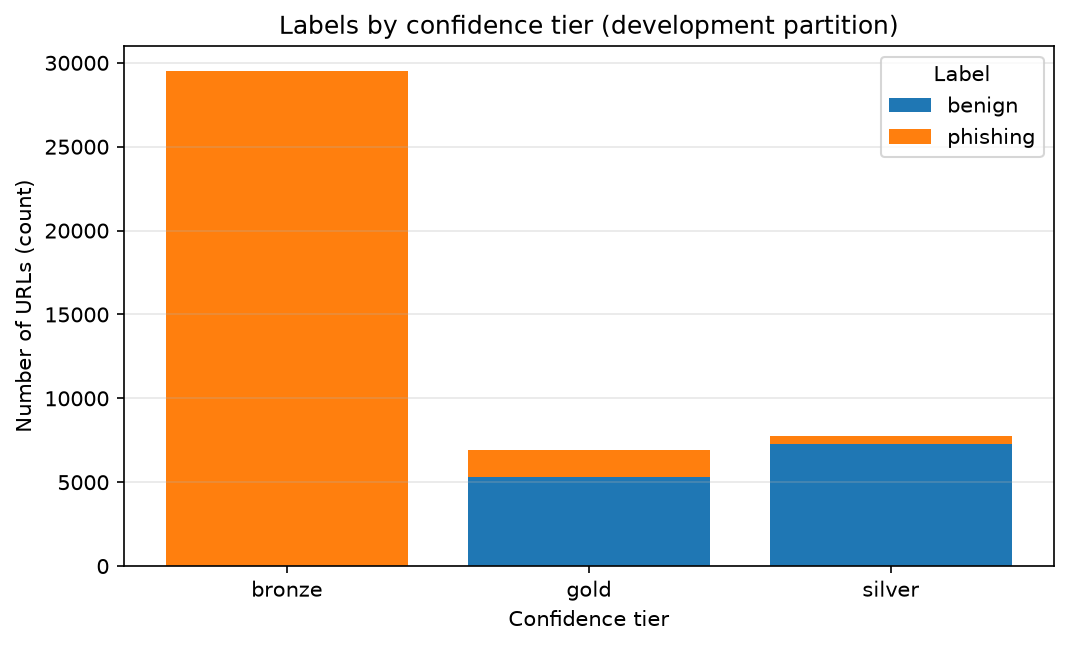

In [6]:
h1 = pd.crosstab(dev_part["tier"], dev_part["label"])
h1["phishing %"] = (100 * h1["phishing"] / h1.sum(axis=1)).round(1)
print("H1 - rows and phishing share by tier (development, all tiers):")
display(h1)

fig = px.bar(h1.reset_index(), x="tier", y=["benign", "phishing"], barmode="stack",
             title="Labels by confidence tier (development partition)",
             labels={"value": "Number of URLs (count)", "tier": "Confidence tier", "variable": "Label"})
fig.write_html("figures/fig_03_1_labels_by_tier.html", include_plotlyjs="cdn")
fig

fig_m, ax = plt.subplots(figsize=(8, 4.5))
bottom = np.zeros(len(h1))
for col in ["benign", "phishing"]:
    ax.bar(h1.index, h1[col].values, bottom=bottom, label=col)
    bottom += h1[col].values
ax.set_title("Labels by confidence tier (development partition)")
ax.set_xlabel("Confidence tier")
ax.set_ylabel("Number of URLs (count)")
ax.legend(title="Label")
ax.grid(axis="y", alpha=0.3)
save_static(fig_m, "fig_03_1_labels_by_tier.png")

H1 - phishing rows and share with a date (development):


,phishing_rows,dated_share
tier,,
bronze,29510,0.5
gold,1619,1.0
silver,481,1.0


H1 - scenario mix of phishing rows by tier (counts and % of the tier's phishing rows):


tier,bronze,gold,silver,bronze %,gold %,silver %
scenario,,,,,,
bank,936,155,92,3.2,9.6,19.1
delivery,17,0,1,0.1,0.0,0.2
ecommerce,758,18,27,2.6,1.1,5.6
gaming,389,0,3,1.3,0.0,0.6
gov,14,0,2,0.0,0.0,0.4
other,27270,1443,351,92.4,89.1,73.0
social,97,1,4,0.3,0.1,0.8
tax,8,1,0,0.0,0.1,0.0
telecom,21,1,1,0.1,0.1,0.2


Chi-square, scenario x tier (gold vs silver, phishing only): chi2 = 105.7, df = 8, asymptotic p = 2.87e-19, smallest expected count = 0.2
Permutation p-value (2,000 shuffles of tier among phishing rows): 0.0005


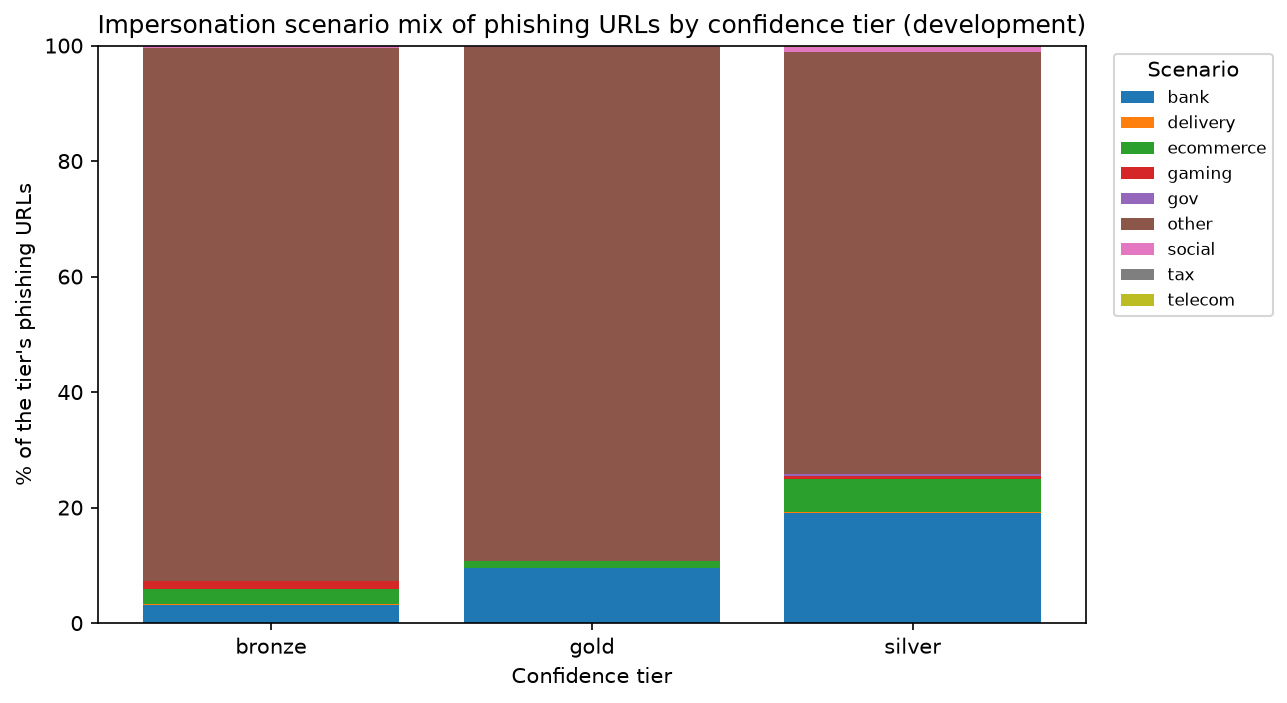

In [7]:
ph_all = dev_part[dev_part["label"] == "phishing"]
dated_share = (ph_all.assign(d=ph_all["collected_at"].str.strip() != "").groupby("tier")["d"]
               .agg(phishing_rows="size", dated_share="mean").round(3))
print("H1 - phishing rows and share with a date (development):")
display(dated_share)
assert dated_share.loc["gold", "dated_share"] == 1.0 and dated_share.loc["silver", "dated_share"] == 1.0

sc = pd.crosstab(ph_all["scenario"], ph_all["tier"])
sc_pct = (100 * sc / sc.sum()).round(1)
print("H1 - scenario mix of phishing rows by tier (counts and % of the tier's phishing rows):")
display(pd.concat([sc, sc_pct.add_suffix(" %")], axis=1))
ph_gs = ph_all.loc[ph_all["tier"].isin(["gold", "silver"]), ["scenario", "tier"]].reset_index(drop=True)
ct_obs = pd.crosstab(ph_gs["scenario"], ph_gs["tier"])
chi2, p_chi, dof, expected = stats.chi2_contingency(ct_obs.values, correction=False)
rng_mc = np.random.RandomState(SEED)
tiers_mc = ph_gs["tier"].to_numpy(dtype=object).copy(); scen_mc = ph_gs["scenario"].to_numpy(dtype=object)
null_chi = []
for _ in range(2000):
    rng_mc.shuffle(tiers_mc)
    null_chi.append(stats.chi2_contingency(pd.crosstab(scen_mc, tiers_mc).values, correction=False)[0])
p_mc = (1 + np.sum(np.array(null_chi) >= chi2)) / (1 + len(null_chi))
print(f"Chi-square, scenario x tier (gold vs silver, phishing only): chi2 = {chi2:.1f}, df = {dof}, "
      f"asymptotic p = {p_chi:.2e}, smallest expected count = {expected.min():.1f}")
print(f"Permutation p-value (2,000 shuffles of tier among phishing rows): {p_mc:.4f}")

long_sc = sc_pct.reset_index().melt(id_vars="scenario", var_name="tier", value_name="pct")
fig = px.bar(long_sc, x="tier", y="pct", color="scenario", barmode="stack",
             title="Impersonation scenario mix of phishing URLs by confidence tier (development)",
             labels={"tier": "Confidence tier", "pct": "% of the tier's phishing URLs", "scenario": "Scenario"})
fig.write_html("figures/fig_03_2_scenario_by_tier.html", include_plotlyjs="cdn")
fig

fig_m, ax = plt.subplots(figsize=(8.5, 5))
bottom = np.zeros(sc_pct.shape[1])
for scen in sc_pct.index:
    vals = sc_pct.loc[scen].values
    ax.bar(sc_pct.columns, vals, bottom=bottom, label=scen)
    bottom += vals
ax.set_title("Impersonation scenario mix of phishing URLs by confidence tier (development)")
ax.set_xlabel("Confidence tier")
ax.set_ylabel("% of the tier's phishing URLs")
ax.set_ylim(0, 100)
ax.legend(title="Scenario", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
save_static(fig_m, "fig_03_2_scenario_by_tier.png")

H2 - median and IQR by label, stratified by tier (development):


,tier,variable,n benign,median benign,IQR benign,n phishing,median phishing,IQR phishing,P(phishing > benign),Mann-Whitney p
0,gold,url_len (characters),5301,23.0,9.0,1619,13.0,8.0,0.152,0.0e+00
1,gold,num_dots (count),5301,3.0,0.0,1619,1.0,1.0,0.113,0.0e+00
2,gold,num_subdomains (labels),5301,1.0,0.0,1619,0.0,1.0,0.242,1.1e-263
3,silver,url_len (characters),7264,12.0,5.0,481,14.0,6.0,0.657,5.3e-31
4,silver,num_dots (count),7264,1.0,0.0,481,1.0,1.0,0.582,4.7e-19
5,silver,num_subdomains (labels),7264,0.0,0.0,481,0.0,1.0,0.664,0.0e+00


Share of URLs with at least two subdomain labels, or at least three dots (development):


,two_or_more_subdomains,three_or_more_dots
label,,
benign,8.3,31.9
phishing,1.6,2.6


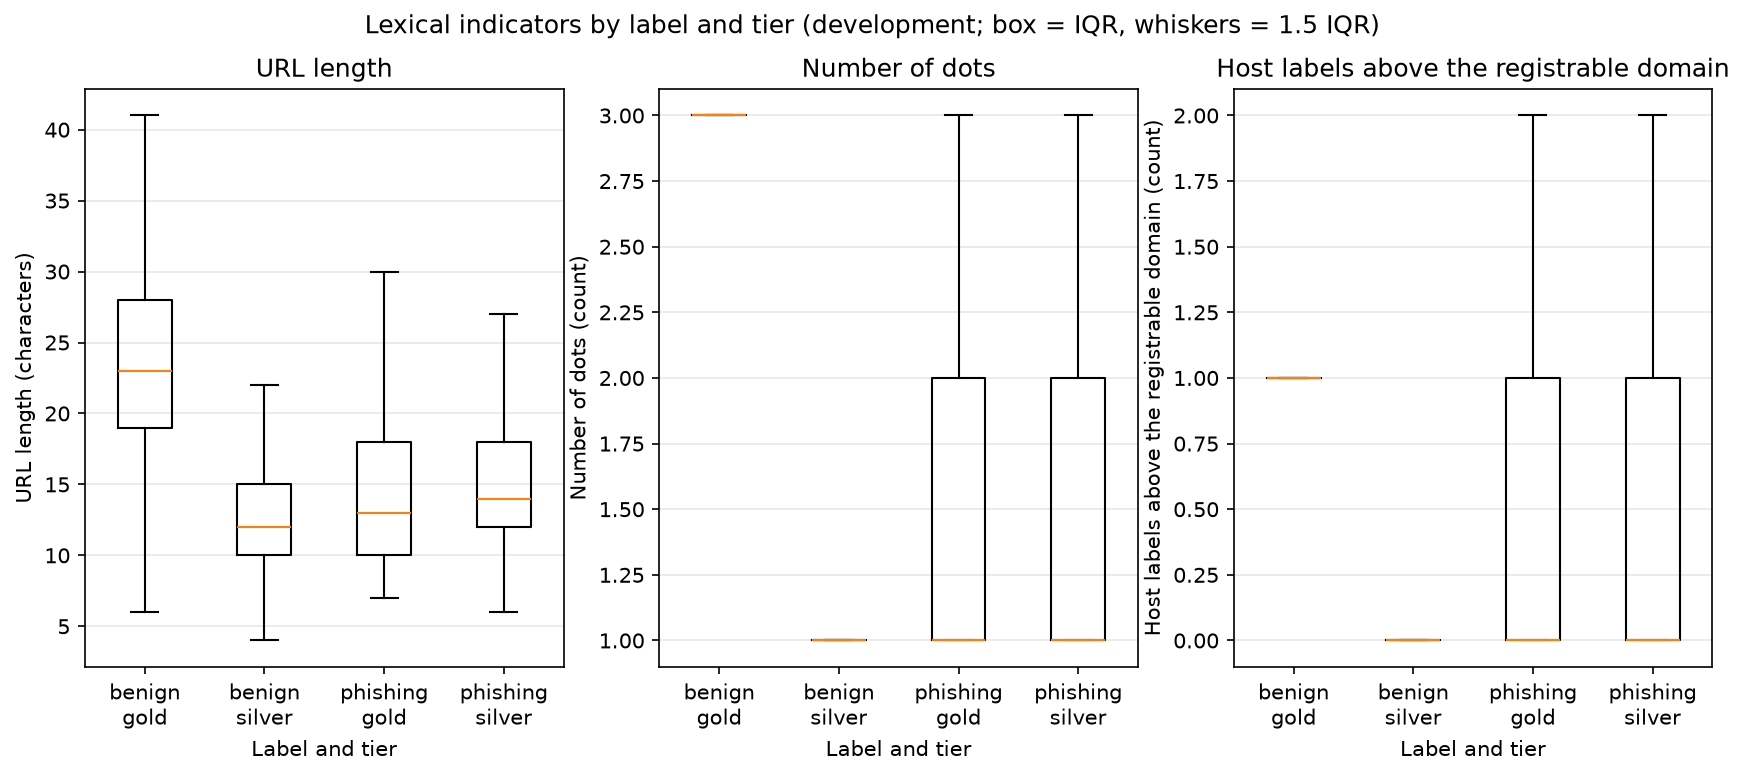

In [8]:
rows = []
for tier in ["gold", "silver"]:
    for var, name in [("f_url_len", "url_len (characters)"), ("f_num_dots", "num_dots (count)"),
                      ("f_num_subdomains", "num_subdomains (labels)")]:
        b = dev.loc[(dev.tier == tier) & (dev.y == 0), var]
        p = dev.loc[(dev.tier == tier) & (dev.y == 1), var]
        test_res = stats.mannwhitneyu(p, b, alternative="two-sided")
        rows.append([tier, name, len(b), b.median(), b.quantile(.75) - b.quantile(.25),
                     len(p), p.median(), p.quantile(.75) - p.quantile(.25),
                     round(test_res.statistic / (len(p) * len(b)), 3), test_res.pvalue])
h2 = pd.DataFrame(rows, columns=["tier", "variable", "n benign", "median benign", "IQR benign",
                                 "n phishing", "median phishing", "IQR phishing",
                                 "P(phishing > benign)", "Mann-Whitney p"])
print("H2 - median and IQR by label, stratified by tier (development):")
display(h2.assign(**{"Mann-Whitney p": h2["Mann-Whitney p"].map(lambda v: f"{v:.1e}")}).round(3))
flags = dev.assign(two_or_more_subdomains=dev["f_num_subdomains"] >= 2, three_or_more_dots=dev["f_num_dots"] >= 3)
print("Share of URLs with at least two subdomain labels, or at least three dots (development):")
display((100 * flags.groupby("label")[["two_or_more_subdomains", "three_or_more_dots"]].mean()).round(1))

long = dev[["tier", "label", "f_url_len", "f_num_dots", "f_num_subdomains"]].melt(
    id_vars=["tier", "label"], var_name="variable", value_name="value")
fig = px.box(long, x="label", y="value", color="tier", facet_col="variable", points=False,
             title="Lexical indicators by label and tier (development; units shown per panel)",
             labels={"label": "Label", "value": "Value (characters for URL length; count otherwise)", "tier": "Tier"})
fig.update_yaxes(matches=None, showticklabels=True)
fig.write_html("figures/fig_03_3_h2_indicators.html", include_plotlyjs="cdn")
fig

panels = [("f_url_len", "URL length", "characters"), ("f_num_dots", "Number of dots", "count"),
          ("f_num_subdomains", "Host labels above the registrable domain", "count")]
fig_m, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, (v, name, unit) in zip(axes, panels):
    data, names = [], []
    for lab in ["benign", "phishing"]:
        for tier in ["gold", "silver"]:
            data.append(dev.loc[(dev["label"] == lab) & (dev["tier"] == tier), v].values)
            names.append(f"{lab}\n{tier}")
    ax.boxplot(data, tick_labels=names, showfliers=False)
    ax.set_title(name)
    ax.set_xlabel("Label and tier")
    ax.set_ylabel(f"{name} ({unit})")
    ax.grid(axis="y", alpha=0.3)
fig_m.suptitle("Lexical indicators by label and tier (development; box = IQR, whiskers = 1.5 IQR)")
save_static(fig_m, "fig_03_3_h2_indicators.png")

H3 - dated phishing URLs (development) by impersonation scenario:


,n,median_url_len,IQR_url_len,median_subdomains,IQR_subdomains
scenario,,,,,
bank,247,19.0,6.0,1.0,1.0
delivery,1,23.0,0.0,1.0,0.0
ecommerce,45,18.0,5.0,0.0,1.0
gaming,3,14.0,3.5,0.0,0.0
gov,2,19.5,1.5,0.0,0.0
other,1794,13.0,7.0,0.0,1.0
social,5,26.0,3.0,0.0,1.0
tax,1,12.0,0.0,0.0,0.0
telecom,2,20.0,2.0,0.0,0.0


Kruskal-Wallis over 3 scenarios with n >= 20: url_len H = 243.9 (p = 1.08e-53); subdomains H = 196.8 (p = 1.88e-43)


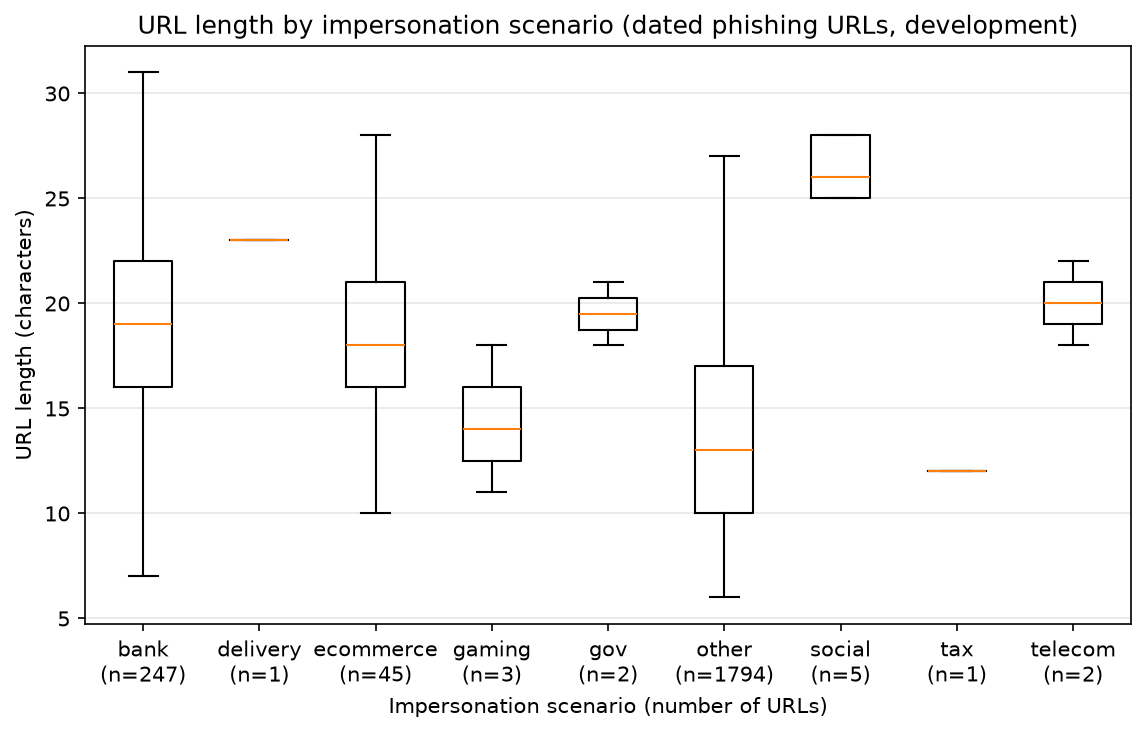

In [9]:
ph = dev[dev["y"] == 1]
assert ph["dt"].notna().all(), "All development phishing rows are expected to be dated"
h3 = ph.groupby("scenario").agg(n=("url", "size"),
                                median_url_len=("f_url_len", "median"),
                                IQR_url_len=("f_url_len", lambda s: s.quantile(.75) - s.quantile(.25)),
                                median_subdomains=("f_num_subdomains", "median"),
                                IQR_subdomains=("f_num_subdomains", lambda s: s.quantile(.75) - s.quantile(.25)))
print("H3 - dated phishing URLs (development) by impersonation scenario:")
display(h3)
big = [g for _, g in ph.groupby("scenario") if len(g) >= 20]
kw_len = stats.kruskal(*[g["f_url_len"] for g in big])
kw_sub = stats.kruskal(*[g["f_num_subdomains"] for g in big])
print(f"Kruskal-Wallis over {len(big)} scenarios with n >= 20: url_len H = {kw_len.statistic:.1f} "
      f"(p = {kw_len.pvalue:.2e}); subdomains H = {kw_sub.statistic:.1f} (p = {kw_sub.pvalue:.2e})")

fig = px.box(ph.assign(scenario_n=ph["scenario"] + " (n=" + ph.groupby("scenario")["y"].transform("size").astype(str) + ")"),
             x="scenario_n", y="f_url_len", points=False,
             title="URL length by impersonation scenario (dated phishing URLs, development)",
             labels={"scenario_n": "Scenario (number of URLs)", "f_url_len": "URL length (characters)"})
fig.write_html("figures/fig_03_4_h3_length_by_scenario.html", include_plotlyjs="cdn")
fig

order = sorted(ph["scenario"].unique())
groups_len = [ph.loc[ph["scenario"] == s, "f_url_len"].values for s in order]
fig_m, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(groups_len, tick_labels=[f"{s}\n(n={len(g)})" for s, g in zip(order, groups_len)], showfliers=False)
ax.set_title("URL length by impersonation scenario (dated phishing URLs, development)")
ax.set_xlabel("Impersonation scenario (number of URLs)")
ax.set_ylabel("URL length (characters)")
ax.grid(axis="y", alpha=0.3)
save_static(fig_m, "fig_03_4_h3_length_by_scenario.png")

**Hypotheses from the brief, tested as written.**

| Hypothesis (brief) | Evidence (development) | Status |
|---|---|---|
| H1: Tier changes the apparent threat profile. | Phishing share: bronze 100 %, gold 23 %, silver 6 %. Scenario mix, gold against silver: chi-square 105.7, df 8, permutation p ≤ 0.0005. | Supported |
| H2: Lexical indicators differ between phishing and benign. | Mann-Whitney (Mann & Whitney, 1947): p < 0.001 in all six comparisons; direction depends on tier (silver phishing longer, median 14 against 12; gold shorter, 13 against 23). No single direction holds across tiers. | Supported |
| H3: Scenarios differ in URL structure. | Kruskal-Wallis (Kruskal & Wallis, 1952), dated phishing: median length bank 19, e-commerce 18, other 13; H = 243.9 (length) and 196.8 (subdomains), p < 0.001. | Supported (dated phishing only) |

**What this means for the stakeholder.** Structure differs: 2.6 % of phishing URLs have three or more dots, against 31.9 % of benign URLs; the direction changes with the benign source, so no fixed rule should be built in.

## 4. Features

Inputs come from `url_features.py`, which uses the Public Suffix List (Public Suffix List, 2026; publicsuffixlist, 2026). Checks use development rows only.

| Feature (as built) | Why it should help | Agreement with dataset column |
|---|---|---|
| `url_len`: characters after a leading scheme | Long, cluttered addresses often hide the real host | 12,997 of 14,665 (deliberate: column keeps the scheme) |
| `num_dots`: `.` characters in the URL | Stacked subdomains add dots | 14,665 of 14,665; also counts path dots |
| `num_subdomains`: host labels minus registrable-domain labels (ICANN PSL) | Impersonation adds brand names as subdomains | 14,631 of 14,665; 33 of 34 differences are `.vn` hosts |
| `has_at`: 1 if `@` appears anywhere | `@` can hide the true destination | 14,665 of 14,665; nearly constant |
| `tld` (Model B): last host label | Some top-level domains are abused more | 14,665 of 14,665; `x.gov.vn` gives `vn` |

**Leakage check.** Label, label-derived, date, split, rank, channel, language and free-text columns are excluded (such as `label`, `tier` and `status`).

In [10]:
# Feature checks use development rows only: the benchmark on which the model is trained and validated.
F_dev = uf.features_frame(dev["url"])

def dataset_int(c):
    return dev[c].astype(float).astype(int)

checks = pd.DataFrame([
    ["url_len (model input, scheme removed)", int((F_dev["url_len"] == dataset_int("url_len")).sum())],
    ["url_len (dataset definition, scheme kept)", int((dev["url"].str.len() == dataset_int("url_len")).sum())],
    ["num_dots", int((F_dev["num_dots"] == dataset_int("num_dots")).sum())],
    ["has_at", int((F_dev["has_at"] == dataset_int("has_at")).sum())],
    ["has_ip", int((F_dev["has_ip"] == dataset_int("has_ip")).sum())],
    ["tld", int((F_dev["tld"] == dev["tld"]).sum())],
    ["num_subdomains", int((F_dev["num_subdomains"] == dataset_int("num_subdomains")).sum())],
], columns=["feature", "rows equal to the dataset column"])
checks["rows in development benchmark"] = len(dev)
display(checks)
chk = dict(zip(checks["feature"], checks["rows equal to the dataset column"]))
assert chk["url_len (dataset definition, scheme kept)"] == len(dev)
assert chk["num_dots"] == len(dev) and chk["has_at"] == len(dev) and chk["has_ip"] == len(dev)
assert chk["tld"] == len(dev)

mism = F_dev["num_subdomains"].values != dataset_int("num_subdomains").values
print(f"num_subdomains disagreements with the dataset column: {int(mism.sum())} of {len(dev)}")
print("Top-level domains of the disagreeing rows (no URLs shown):")
display(F_dev.loc[mism, "tld"].value_counts().head(8).rename("rows").to_frame())
print(f"Development URLs containing '@': {int(dev['url'].str.contains('@').sum())} of {len(dev)}")

,feature,rows equal to the dataset column,rows in development benchmark
0,"url_len (model input, scheme removed)",12997,14665
1,"url_len (dataset definition, scheme kept)",14665,14665
2,num_dots,14665,14665
3,has_at,14665,14665
4,has_ip,14665,14665
5,tld,14665,14665
6,num_subdomains,14631,14665


num_subdomains disagreements with the dataset column: 34 of 14665
Top-level domains of the disagreeing rows (no URLs shown):


,rows
tld,
vn,33
ar,1


Development URLs containing '@': 3 of 14665


In [11]:
EXCLUDED = ["label", "tier", "source", "scenario", "label_source", "status", "impersonated_org", "abuse_type",
            "suspicious_tld", "split", "collected_at", "scraped_at", "rank", "channel", "lang",
            "text", "msg_len", "gen_model", "has_url", "id", "is_https"]
X_probe = pd.DataFrame({"url": dev["url"].head(20)})
out_cols = list(uf.UrlFeatures(columns=INPUTS_B).fit_transform(X_probe).columns)
assert set(out_cols) == set(INPUTS_B)
assert not (set(out_cols) & set(EXCLUDED)), "An excluded column reached the model inputs"
assert (dev["f_num_dots"] == dev["num_dots"].astype(float).astype(int)).all()
assert (dev["f_has_at"] == dev["has_at"].astype(float).astype(int)).all()
print("Model B inputs:", out_cols)
print("Development URLs containing '@':", int(dev["f_has_at"].sum()),
      "| of which phishing:", int(dev.loc[dev["f_has_at"] == 1, "y"].sum()))
print("Leakage check: no input is a label, a split indicator, a date or a source field.")

Model B inputs: ['url_len', 'num_dots', 'num_subdomains', 'has_at', 'tld']
Development URLs containing '@': 3 | of which phishing: 0
Leakage check: no input is a label, a split indicator, a date or a source field.


**What this means for the stakeholder.** The inputs are counts and the top-level domain, all known when a URL arrives. `@` is nearly absent, so it is not a usable rule.

## 5. Split and baseline

**Why temporal.** The official split puts the oldest dated phishing in `train` and the newest in `test` (Nguyen Vu, 2026). A random split would validate on older campaigns than the model learns from, so the primary protocol validates on domains whose first phishing URL is dated on or after 31 December 2021. Because the split follows domains, four URLs dated 31 December 2021 fall in validation and four URLs from 2022 stay in training.

**Groups.** All rows of one registrable domain stay on one side of a split. Undated benign groups (Tranco-based sources, Le Pochat et al., 2019, and tinnhiem_web) go 30 % to validation at random.

**Today's rule.** Not documented, so none is modelled or claimed; the naive baselines are technical references only.

In [12]:
phish_time = dev[dev["y"] == 1].groupby("grp")["dt"].min()
all_time = dev.groupby("grp")["dt"].min()

def temporal_mask(mode, cutoff, undated_val_share=0.30):
    times = phish_time if mode == "phishing" else all_time
    gt = dev["grp"].map(times)
    dated = gt.notna().values
    undated_groups = np.array(sorted(dev.loc[~dated, "grp"].unique()))
    rng = np.random.RandomState(SEED)
    chosen = set(rng.permutation(undated_groups)[: int(round(undated_val_share * len(undated_groups)))])
    is_val = np.where(dated, (gt >= cutoff).values, dev["grp"].isin(chosen).values)
    return is_val.astype(bool)

def check_split(is_val, mode, cutoff):
    tr = ~is_val
    assert set(dev.loc[is_val, "grp"]).isdisjoint(set(dev.loc[tr, "grp"])), "A registrable domain is on both sides"
    times = phish_time if mode == "phishing" else all_time
    gt = dev["grp"].map(times).values
    dated = ~pd.isna(gt)
    assert (gt[dated & is_val] >= np.datetime64(cutoff)).all()
    assert (gt[dated & tr] < np.datetime64(cutoff)).all()
    assert dev.loc[is_val, "y"].sum() > 0 and dev.loc[tr, "y"].sum() > 0

PROTOCOLS = {
    PRIMARY: temporal_mask("phishing", CUTOFF_PRIMARY),
    "T2 sensitivity: phishing dates, cutoff 2020-12-31": temporal_mask("phishing", CUTOFF_SENS),
    "T3 sensitivity: all dated groups, cutoff 2021-12-31": temporal_mask("all", CUTOFF_PRIMARY),
}
for (name, m), (mode, cut) in zip(PROTOCOLS.items(),
                                   [("phishing", CUTOFF_PRIMARY), ("phishing", CUTOFF_SENS), ("all", CUTOFF_PRIMARY)]):
    check_split(m, mode, cut)

OUTER = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(dev, dev["y"], dev["grp"]))
for tr_i, va_i in OUTER:
    assert set(dev.loc[tr_i, "grp"]).isdisjoint(set(dev.loc[va_i, "grp"]))

split_rows = []
ref_fold0 = np.isin(np.arange(len(dev)), OUTER[0][1])
for name, is_val in list(PROTOCOLS.items()) + [(R_NAME + " (fold 0 shown)", ref_fold0)]:
    tr = ~is_val
    earliest = dev.loc[is_val & (dev["y"] == 1).values, "dt"].min()
    split_rows.append([name, int(tr.sum()), int(dev.loc[tr, "y"].sum()), int(is_val.sum()),
                       int(dev.loc[is_val, "y"].sum()), round(100 * dev.loc[is_val, "y"].mean(), 1),
                       str(earliest.date()) if pd.notna(earliest) else "-"])
split_table = pd.DataFrame(split_rows, columns=["protocol", "train rows", "train phishing", "validation rows",
                                                "validation phishing", "validation phishing %",
                                                "earliest validation phishing"])
display(split_table)

,protocol,train rows,train phishing,validation rows,validation phishing,validation phishing %,earliest validation phishing
0,"T1 primary: phishing dates, cutoff 2021-12-31",9975,1526,4690,574,12.2,2021-12-31
1,"T2 sensitivity: phishing dates, cutoff 2020-12-31",8833,389,5832,1711,29.3,2021-05-10
2,"T3 sensitivity: all dated groups, cutoff 2021-...",10387,1526,4278,574,13.4,2021-12-31
3,R reference: 5 random grouped folds (fold 0 sh...,11732,1680,2933,420,14.3,2020-10-08


Development phishing URLs by first-seen year and role in the primary protocol:


col_0,training,validation
dt,,
2020,389,0
2021,1132,4
2022,4,556
2023,0,11
2024,1,3


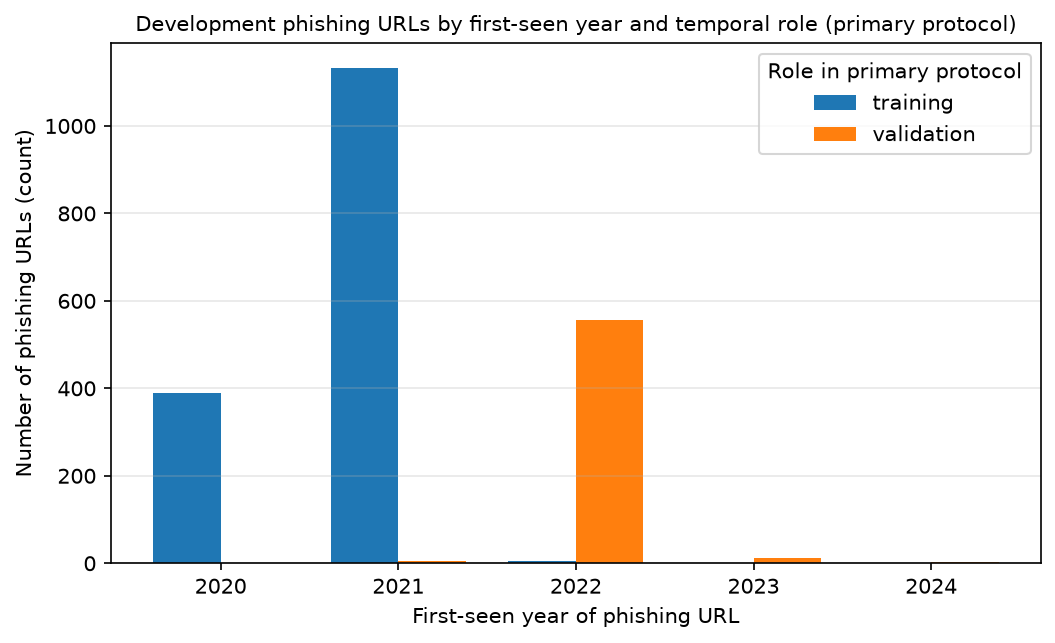

In [13]:
year_tab = pd.crosstab(dev.loc[dev["y"] == 1, "dt"].dt.year,
                       np.where(PROTOCOLS[PRIMARY][(dev["y"] == 1).values], "validation", "training"))
print("Development phishing URLs by first-seen year and role in the primary protocol:")
display(year_tab)
fig = px.bar(year_tab.reset_index().melt(id_vars="dt", var_name="role", value_name="URLs"),
             x="dt", y="URLs", color="role", barmode="group",
             title="Development phishing URLs by first-seen year and temporal role (primary protocol)",
             labels={"dt": "First-seen year", "URLs": "Number of phishing URLs (count)", "role": "Role"})
fig.write_html("figures/fig_05_1_temporal_roles.html", include_plotlyjs="cdn")
fig

fig_m, ax = plt.subplots(figsize=(8, 4.5))
x_pos = np.arange(len(year_tab.index))
w = 0.38
for i, role in enumerate(year_tab.columns):
    ax.bar(x_pos + (i - 0.5) * w, year_tab[role].values, w, label=role)
ax.set_xticks(x_pos, [str(v) for v in year_tab.index])
ax.set_title("Development phishing URLs by first-seen year and temporal role (primary protocol)", fontsize=10)
ax.set_xlabel("First-seen year of phishing URL")
ax.set_ylabel("Number of phishing URLs (count)")
ax.legend(title="Role in primary protocol")
ax.grid(axis="y", alpha=0.3)
save_static(fig_m, "fig_05_1_temporal_roles.png")

In [14]:
def cost_for(yy, pred, cost=COST):
    tp = np.sum(pred & (yy == 1)); fp = np.sum(pred & (yy == 0))
    fn = np.sum(~pred & (yy == 1)); tn = np.sum(~pred & (yy == 0))
    return 1000 * (fp * cost["FP"] + fn * cost["FN"] + tp * cost["TP"] + tn * cost["TN"]) / len(yy)

def summarize_pred(yy, pred, p=None):
    yy = np.asarray(yy); pred = np.asarray(pred, dtype=bool)
    tp = int(np.sum(pred & (yy == 1))); fp = int(np.sum(pred & (yy == 0)))
    fn = int(np.sum(~pred & (yy == 1))); tn = int(np.sum(~pred & (yy == 0)))
    out = {"TP": tp, "FP": fp, "FN": fn, "TN": tn,
           "precision": tp / (tp + fp) if tp + fp else np.nan,
           "recall": tp / (tp + fn), "FPR": fp / (fp + tn),
           "cost_per_1000": cost_for(yy, pred)}
    if p is not None:
        out["AUC"] = roc_auc_score(yy, p)
        out["Brier"] = brier_score_loss(yy, p)
    return out

is_val_T1 = PROTOCOLS[PRIMARY]
yv = dev.loc[is_val_T1, "y"].values
base_maj = summarize_pred(yv, np.zeros(len(yv), dtype=bool))
base_has = summarize_pred(yv, dev.loc[is_val_T1, "f_has_at"].values.astype(bool))
cols_base = ["TP", "FP", "FN", "TN", "precision", "recall", "cost_per_1000"]
base_tab = pd.DataFrame([
    {"baseline (primary validation)": "Majority class (always benign)", **{k: base_maj[k] for k in cols_base}},
    {"baseline (primary validation)": "Heuristic: has_at = 1", **{k: base_has[k] for k in cols_base}}]).round(3)
print(f"Naive baselines on primary validation ({len(yv)} URLs, {int(yv.sum())} phishing). No operational rule is documented.")
display(base_tab)

Naive baselines on primary validation (4690 URLs, 574 phishing). No operational rule is documented.


,baseline (primary validation),TP,FP,FN,TN,precision,recall,cost_per_1000
0,Majority class (always benign),0,0,574,4116,NaN,0.0,12238.806
1,Heuristic: has_at = 1,0,1,574,4115,0.0,0.0,12245.203


**What this means for the stakeholder.** Validating on phishing first seen on or after the cutoff is closer to real use than a random split. Only 15 development phishing URLs date from 2023 or later; all 487 test phishing URLs do.

## 6. Candidate models

Four scikit-learn pipelines (Pedregosa et al., 2011): logistic regression (LR; Hosmer et al., 2013) and gradient boosting (HGB; Friedman, 2001), each without (A) and with (B) the top-level domain.

**Nested procedure.** Three grouped folds give out-of-fold (OOF) predictions for the training part. Within each fold, hyperparameters are chosen by grouped CV on log loss, using only the other folds. Calibration (sigmoid or isotonic; Niculescu-Mizil & Caruana, 2005) and the threshold come from the OOF predictions. Validation rows are scored once with the frozen threshold. The test set plays no part.

The lowest primary validation cost wins; ties within 1 % go to the simpler model. Those costs are optimistic, because they drive the choice.

**Tools in the triage workflow.** Python and scikit-learn let the team rebuild and recheck the scorer on each new labelled batch. joblib stores the whole pipeline in one file, so a later tool can score raw URLs without retraining. Plotly and matplotlib produce the charts used to monitor recall (Section 10). No SOC platform (SIEM, ticketing or mail gateway) is connected to these files; that integration is not implemented.


In [15]:
FX = pd.DataFrame({"url_len": dev["f_url_len"].values, "num_dots": dev["f_num_dots"].values,
                   "num_subdomains": dev["f_num_subdomains"].values, "has_at": dev["f_has_at"].values,
                   "tld": dev["f_tld"].values})
y = dev["y"].values
G = dev["grp"].values

def make_model(kind, with_tld, from_url=False):
    cols = INPUTS_B if with_tld else INPUTS_A
    transformers = [("num", StandardScaler(), INPUTS_A)]
    if with_tld:
        transformers.append(("tld", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                                                   sparse_output=False), ["tld"]))
    if kind == "lr":
        est = LogisticRegression(max_iter=2000, random_state=SEED)
    else:
        est = HistGradientBoostingClassifier(max_iter=200, min_samples_leaf=50, random_state=SEED)
    steps = [("features", uf.UrlFeatures(columns=cols))] if from_url else []
    steps += [("prep", ColumnTransformer(transformers)), ("model", est)]
    return Pipeline(steps)

def best_threshold(yy, p):
    costs = np.array([cost_for(yy, p >= t) for t in THRESH])
    i = int(np.argmin(costs))
    return float(THRESH[i]), float(costs[i])

def select_params(kind, with_tld, X, yy, g):
    gs = GridSearchCV(make_model(kind, with_tld), GRIDS[kind], cv=GroupKFold(n_splits=3),
                      scoring="neg_log_loss", refit=False)
    gs.fit(X, yy, groups=g)
    return gs.best_params_

def calibrated(kind, with_tld, method, params, X, yy, g, from_url=False):
    inner = list(GroupKFold(n_splits=3).split(X, yy, g))
    base = make_model(kind, with_tld, from_url).set_params(**params)
    return CalibratedClassifierCV(base, method=method, cv=inner).fit(X, yy)

def nested_oof(kind, with_tld, X, yy, g):
    # Out-of-fold predictions for both calibration methods, with nested hyperparameter selection.
    # In each grouped fold, hyperparameters are selected using only the other two folds; the held-out fold is predicted once.
    folds = list(GroupKFold(n_splits=3).split(X, yy, g))
    oof = {m: np.zeros(len(yy)) for m in CAL_METHODS}
    fold_params = []
    for a, b in folds:
        params_a = select_params(kind, with_tld, X.iloc[a], yy[a], g[a])
        fold_params.append(params_a)
        for m in CAL_METHODS:
            model_a = calibrated(kind, with_tld, m, params_a, X.iloc[a], yy[a], g[a])
            oof[m][b] = model_a.predict_proba(X.iloc[b])[:, 1]
    return oof, folds, fold_params

def choose_method(yy, oof, folds):
    overall = brier_score_loss(yy, oof["isotonic"]) < brier_score_loss(yy, oof["sigmoid"])
    per_fold = all(brier_score_loss(yy[b], oof["isotonic"][b]) < brier_score_loss(yy[b], oof["sigmoid"][b])
                   for _, b in folds)
    return "isotonic" if (overall and per_fold) else "sigmoid"

def fit_eval(cname, kind, with_tld, tr, va):
    cols = INPUTS_B if with_tld else INPUTS_A
    X_tr, y_tr, g_tr = FX.loc[tr, cols], y[tr], G[tr]
    X_va, y_va = FX.loc[va, cols], y[va]
    oof, folds, _ = nested_oof(kind, with_tld, X_tr, y_tr, g_tr)   # hyperparameters never see the held-out fold
    method = choose_method(y_tr, oof, folds)
    thr, oof_cost = best_threshold(y_tr, oof[method])              # threshold from nested out-of-fold predictions
    params = select_params(kind, with_tld, X_tr, y_tr, g_tr)       # final hyperparameters: training part only
    model = calibrated(kind, with_tld, method, params, X_tr, y_tr, g_tr)
    p_va = model.predict_proba(X_va)[:, 1]
    res = summarize_pred(y_va, p_va >= thr, p_va)
    res.update(config=cname, calibration=method, threshold=thr, oof_cost_per_1000=round(oof_cost, 1),
               hyperparameters=str(params), n_train=int(tr.sum()), n_val=int(va.sum()),
               prevalence_val=round(float(y_va.mean()), 4))
    return res, p_va, model

In [16]:
RESULTS, PRED, MODELS = [], {}, {}
t_start = time.time()
for pname, is_val in PROTOCOLS.items():
    tr = ~is_val
    for cname, (kind, with_tld) in CONFIGS.items():
        res, p_va, mdl = fit_eval(cname, kind, with_tld, tr, is_val)
        res["protocol"] = pname
        RESULTS.append(res)
        PRED[(pname, cname)] = (is_val, p_va, res["threshold"])
        MODELS[(pname, cname)] = mdl
print(f"Temporal protocols finished in {time.time() - t_start:.0f} s")

R_PRED, R_FOLD_MODELS, R_THR = {}, {}, {}
t_start = time.time()
for cname, (kind, with_tld) in CONFIGS.items():
    p_oof = np.full(len(y), np.nan); thr_row = np.full(len(y), np.nan)
    models, masks, thrs, cals = [], [], [], []
    for tr_i, va_i in OUTER:
        tr = np.zeros(len(y), bool); tr[tr_i] = True
        va = np.zeros(len(y), bool); va[va_i] = True
        res, p, mdl = fit_eval(cname, kind, with_tld, tr, va)
        p_oof[va] = p; thr_row[va] = res["threshold"]
        models.append(mdl); masks.append(va); thrs.append(res["threshold"]); cals.append(res["calibration"])
    pooled = summarize_pred(y, p_oof >= thr_row, p_oof)
    pooled.update(config=cname, calibration=f"per fold: {cals}",
                  threshold=f"per fold: {[round(t, 2) for t in thrs]}",
                  oof_cost_per_1000=np.nan, hyperparameters="per fold", n_train=np.nan, n_val=len(y),
                  prevalence_val=round(float(y.mean()), 4), protocol=R_NAME)
    RESULTS.append(pooled)
    R_PRED[cname] = (p_oof, thr_row)
    R_FOLD_MODELS[cname] = (models, masks)
    R_THR[cname] = thrs
print(f"Random reference finished in {time.time() - t_start:.0f} s")

res_df = pd.DataFrame(RESULTS)
cols_show = ["config", "calibration", "threshold", "TP", "FP", "FN", "TN", "precision", "recall", "FPR",
             "cost_per_1000", "AUC", "Brier"]
for pname in list(PROTOCOLS) + [R_NAME]:
    print(f"\n{pname}")
    display(res_df.loc[res_df["protocol"] == pname, cols_show].sort_values("cost_per_1000").round(3).reset_index(drop=True))

Temporal protocols finished in 88 s


Random reference finished in 163 s

T1 primary: phishing dates, cutoff 2021-12-31


,config,calibration,threshold,TP,FP,FN,TN,precision,recall,FPR,cost_per_1000,AUC,Brier
0,LR-B,isotonic,0.25,417,167,157,3949,0.714,0.726,0.041,4860.341,0.940,0.048
1,HGB-B,sigmoid,0.24,462,517,112,3599,0.472,0.805,0.126,6187.633,0.935,0.055
2,LR-A,isotonic,0.3,241,40,333,4076,0.858,0.420,0.010,7613.006,0.839,0.066
3,HGB-A,sigmoid,0.34,212,40,362,4076,0.841,0.369,0.010,8200.426,0.840,0.071



T2 sensitivity: phishing dates, cutoff 2020-12-31


,config,calibration,threshold,TP,FP,FN,TN,precision,recall,FPR,cost_per_1000,AUC,Brier
0,LR-A,isotonic,0.24,563,41,1148,4080,0.932,0.329,0.010,20378.086,0.833,0.196
1,LR-B,sigmoid,0.25,193,41,1518,4080,0.825,0.113,0.010,26405.178,0.864,0.241
2,HGB-A,isotonic,0.21,123,28,1588,4093,0.815,0.072,0.007,27478.567,0.789,0.235
3,HGB-B,isotonic,0.41,46,15,1665,4106,0.754,0.027,0.004,28665.981,0.843,0.257



T3 sensitivity: all dated groups, cutoff 2021-12-31


,config,calibration,threshold,TP,FP,FN,TN,precision,recall,FPR,cost_per_1000,AUC,Brier
0,LR-B,isotonic,0.25,415,168,159,3536,0.712,0.723,0.045,5379.850,0.934,0.050
1,HGB-B,isotonic,0.24,390,474,184,3230,0.451,0.679,0.128,8080.879,0.916,0.061
2,LR-A,isotonic,0.27,241,41,333,3663,0.855,0.420,0.011,8353.202,0.817,0.073
3,HGB-A,sigmoid,0.25,212,41,362,3663,0.838,0.369,0.011,8997.195,0.807,0.078



R reference: 5 random grouped folds


,config,calibration,threshold,TP,FP,FN,TN,precision,recall,FPR,cost_per_1000,AUC,Brier
0,LR-B,"per fold: ['isotonic', 'isotonic', 'isotonic',...","per fold: [0.31, 0.27, 0.36, 0.31, 0.23]",1229,325,871,12240,0.791,0.585,0.026,7023.184,0.916,0.063
1,HGB-B,"per fold: ['sigmoid', 'isotonic', 'isotonic', ...","per fold: [0.26, 0.23, 0.21, 0.24, 0.25]",1351,881,749,11684,0.605,0.643,0.070,7370.269,0.913,0.066
2,HGB-A,"per fold: ['sigmoid', 'sigmoid', 'sigmoid', 's...","per fold: [0.26, 0.22, 0.23, 0.22, 0.21]",995,1164,1105,11401,0.461,0.474,0.093,10255.370,0.838,0.086
3,LR-A,"per fold: ['isotonic', 'isotonic', 'isotonic',...","per fold: [0.21, 0.32, 0.3, 0.27, 0.2]",670,172,1430,12393,0.796,0.319,0.014,10331.401,0.819,0.087


In [17]:
primary = res_df[res_df["protocol"] == PRIMARY].sort_values("cost_per_1000").reset_index(drop=True)
best = primary.iloc[0]
tie = primary[(primary["cost_per_1000"] - best["cost_per_1000"]).abs() / best["cost_per_1000"] < 0.01].copy()
tie["pref"] = [0 if c.startswith("LR") else 1 for c in tie["config"]]
tie["model_b"] = [1 if c.endswith("B") else 0 for c in tie["config"]]
best = tie.sort_values(["pref", "model_b"]).iloc[0]
SELECTED = best["config"]
SEL_KIND, SEL_TLD = CONFIGS[SELECTED]
print(f"Selected configuration on the primary validation protocol: {SELECTED} | calibration: {best['calibration']} "
      f"| threshold: {best['threshold']:.2f} | validation cost: {best['cost_per_1000']:.1f} EUR per 1,000 URLs")
print("Random reference, per-fold thresholds for the selected configuration:", [round(t, 2) for t in R_THR[SELECTED]])
display(res_df.loc[res_df["protocol"] == R_NAME, ["config", "calibration", "threshold"]].reset_index(drop=True))

Selected configuration on the primary validation protocol: LR-B | calibration: isotonic | threshold: 0.25 | validation cost: 4860.3 EUR per 1,000 URLs
Random reference, per-fold thresholds for the selected configuration: [0.31, 0.27, 0.36, 0.31, 0.23]


,config,calibration,threshold
0,LR-A,"per fold: ['isotonic', 'isotonic', 'isotonic',...","per fold: [0.21, 0.32, 0.3, 0.27, 0.2]"
1,LR-B,"per fold: ['isotonic', 'isotonic', 'isotonic',...","per fold: [0.31, 0.27, 0.36, 0.31, 0.23]"
2,HGB-A,"per fold: ['sigmoid', 'sigmoid', 'sigmoid', 's...","per fold: [0.26, 0.22, 0.23, 0.22, 0.21]"
3,HGB-B,"per fold: ['sigmoid', 'isotonic', 'isotonic', ...","per fold: [0.26, 0.23, 0.21, 0.24, 0.25]"


**What this means for the stakeholder.** The logistic regression with the top-level domain was cheapest on primary validation. Its threshold varied from 0.23 to 0.36 across random folds; recheck it on each batch.

## 7. Metric and cost of errors

**Metric.** Expected cost per 1,000 URLs at illustrative prices (30 EUR per false positive, 100 EUR per false negative, 5 EUR per true positive, 0 EUR per true negative), with precision and recall. Accuracy is not used: with 14 % phishing, always answering benign looks accurate.

**Threshold.** For calibrated probabilities the cost-minimising threshold is 30 / (30 + 100 − 5) = 0.24. The threshold is learnt from nested OOF predictions on training data and applied once to validation.

**Confusion matrix in business terms.** A true positive is phishing sent to review; a false negative is phishing that passes; a false positive is benign traffic sent to review, costing analyst time. The matrix uses the primary protocol (threshold 0.25); the final model uses 0.22 (Section 8).

In [18]:
yy_t = np.array([0, 0, 0, 1, 1, 1, 1, 1, 0, 1])
pp_t = np.array([1, 0, 1, 0, 0, 1, 1, 1, 1, 0], dtype=bool)
manual = 1000 * (3 * 30 + 3 * 100 + 3 * 5 + 1 * 0) / 10     # FP = 3, FN = 3, TP = 3, TN = 1
assert abs(cost_for(yy_t, pp_t) - manual) < 1e-9
print("Cost formula check on a toy example (3 FP, 3 FN, 3 TP, 1 TN): OK")
print(f"Theoretical threshold: {30 / (30 + 100 - 5):.3f}")

display(res_df.loc[res_df["config"] == SELECTED, ["protocol", "calibration", "threshold", "precision", "recall",
                                                    "FPR", "cost_per_1000", "AUC"]].round(3).reset_index(drop=True))

Cost formula check on a toy example (3 FP, 3 FN, 3 TP, 1 TN): OK
Theoretical threshold: 0.240


,protocol,calibration,threshold,precision,recall,FPR,cost_per_1000,AUC
0,"T1 primary: phishing dates, cutoff 2021-12-31",isotonic,0.25,0.714,0.726,0.041,4860.341,0.940
1,"T2 sensitivity: phishing dates, cutoff 2020-12-31",sigmoid,0.25,0.825,0.113,0.010,26405.178,0.864
2,"T3 sensitivity: all dated groups, cutoff 2021-...",isotonic,0.25,0.712,0.723,0.045,5379.850,0.934
3,R reference: 5 random grouped folds,"per fold: ['isotonic', 'isotonic', 'isotonic',...","per fold: [0.31, 0.27, 0.36, 0.31, 0.23]",0.791,0.585,0.026,7023.184,0.916


In [19]:
# Sensitivity of the threshold to the cost assumptions (selected configuration, in-sample for the random reference)
is_val_p, p_primary, thr_primary = PRED[(PRIMARY, SELECTED)]
p_oof, thr_row = R_PRED[SELECTED]
rows = []
for fp_c in [15.0, 30.0, 60.0]:
    for fn_c in [50.0, 100.0, 200.0]:
        cst = {"FP": fp_c, "FN": fn_c, "TP": COST["TP"], "TN": COST["TN"]}
        fixed = cost_for(y[is_val_p], p_primary >= thr_primary, cst)
        opt_r = max(THRESH, key=lambda t: -cost_for(y, p_oof >= t, cst))
        rows.append([fp_c, fn_c, round(fp_c / (fp_c + fn_c - COST["TP"]), 2), round(float(opt_r), 2),
                     round(fixed, 1), round(cost_for(y, p_oof >= opt_r, cst), 1)])
sens = pd.DataFrame(rows, columns=["C_FP (EUR)", "C_FN (EUR)", "theoretical threshold",
                                   "in-sample optimal threshold (random reference OOF)",
                                   "cost at the frozen threshold (primary validation, EUR/1,000)",
                                   "cost at the in-sample optimum (random reference, EUR/1,000)"])
display(sens)

row_sel = res_df[(res_df["protocol"] == PRIMARY) & (res_df["config"] == SELECTED)].iloc[0]
biz = pd.DataFrame([
    ["Phishing (actual)", int(row_sel["TP"]), int(row_sel["FN"])],
    ["Benign (actual)", int(row_sel["FP"]), int(row_sel["TN"])]],
    columns=["Actual label (URLs, validation)", "Sent to review", "Passed without review"])
print(f"Primary validation, {SELECTED}, threshold {row_sel['threshold']:.2f}: "
      f"{int(row_sel['TP'] + row_sel['FP'])} of {int(row_sel['TP'] + row_sel['FP'] + row_sel['FN'] + row_sel['TN'])} URLs sent to review")
display(biz)

,C_FP (EUR),C_FN (EUR),theoretical threshold,in-sample optimal threshold (random reference OOF),"cost at the frozen threshold (primary validation, EUR/1,000)","cost at the in-sample optimum (random reference, EUR/1,000)"
0,15.0,50.0,0.25,0.25,2652.5,3692.5
1,15.0,100.0,0.14,0.13,4326.2,5207.0
2,15.0,200.0,0.07,0.10,7673.8,5853.7
3,30.0,50.0,0.40,0.28,3186.6,3987.0
4,30.0,100.0,0.24,0.21,4860.3,6958.4
5,30.0,200.0,0.13,0.11,8207.9,9732.4
6,60.0,50.0,0.57,0.64,4254.8,4401.3
7,60.0,100.0,0.39,0.28,5928.6,7557.4
8,60.0,200.0,0.24,0.21,9276.1,13473.9


Primary validation, LR-B, threshold 0.25: 584 of 4690 URLs sent to review


,"Actual label (URLs, validation)",Sent to review,Passed without review
0,Phishing (actual),417,157
1,Benign (actual),167,3949


**What this means for the stakeholder.** Model rankings are more reliable than the euro amounts, which rest on illustrative prices; replace them before any business case.

## 8. Validation and tuning

Cross-validation, grid search and calibration use development data only. The final model and threshold are then fitted on all development rows; the test file is read for the final evaluation.

**Test set status: the requirement is not met.** An earlier version read this test set and reported the same model, threshold (0.22) and cost (7,852 EUR per 1,000 URLs). The corrected procedure reproduces these figures, but the set is neither untouched nor independent. No new, independent sample exists in the repository, none has been simulated, and one should be obtained.

In [20]:
final_cols = INPUTS_B if SEL_TLD else INPUTS_A
X_all = FX[final_cols]
# Nested out-of-fold predictions: each fold selects its own hyperparameters inside its training part.
oof_all, folds_all, fold_params_all = nested_oof(SEL_KIND, SEL_TLD, X_all, y, G)
FINAL_METHOD = choose_method(y, oof_all, folds_all)
FINAL_THR, FINAL_INNER = best_threshold(y, oof_all[FINAL_METHOD])
# Final hyperparameters use all development rows; they do not affect the threshold above.
FINAL_PARAMS = select_params(SEL_KIND, SEL_TLD, X_all, y, G)
final_feat = calibrated(SEL_KIND, SEL_TLD, FINAL_METHOD, FINAL_PARAMS, X_all, y, G)
final_url = calibrated(SEL_KIND, SEL_TLD, FINAL_METHOD, FINAL_PARAMS, dev[["url"]], y, G, from_url=True)

sample = dev.sample(300, random_state=SEED).index
assert np.allclose(final_url.predict_proba(dev.loc[sample, ["url"]])[:, 1],
                   final_feat.predict_proba(FX.loc[sample, final_cols])[:, 1], atol=1e-9), \
    "URL pipeline and feature pipeline disagree"
print(f"Final model: {SELECTED} | final hyperparameters (all development rows): {FINAL_PARAMS} | "
      f"calibration: {FINAL_METHOD} | threshold (nested out-of-fold, all development rows): {FINAL_THR:.2f}")
print(f"Cost on those out-of-fold predictions: {FINAL_INNER:.1f} EUR per 1,000 URLs "
      "(optimistic: the threshold was chosen on these predictions)")
print("Hyperparameters chosen inside each nested fold (training part only):", fold_params_all)

Final model: LR-B | final hyperparameters (all development rows): {'model__C': 10.0} | calibration: isotonic | threshold (nested out-of-fold, all development rows): 0.22
Cost on those out-of-fold predictions: 7213.4 EUR per 1,000 URLs (optimistic: the threshold was chosen on these predictions)
Hyperparameters chosen inside each nested fold (training part only): [{'model__C': 10.0}, {'model__C': 10.0}, {'model__C': 1.0}]


,model,TP,FP,FN,TN,precision,recall,FPR,"cost per 1,000 URLs (EUR)",AUC
0,Final model (LR-B),171,52,316,3793,0.767,0.351,0.014,7852.0,0.911
1,Majority class (always benign),0,0,487,3845,NaN,0.000,0.000,11241.9,NaN
2,Heuristic: has_at = 1,0,2,487,3843,0.000,0.000,0.001,11255.8,NaN


Test recall 0.351, Wilson 95% CI [0.310, 0.395]; test prevalence 11.2%


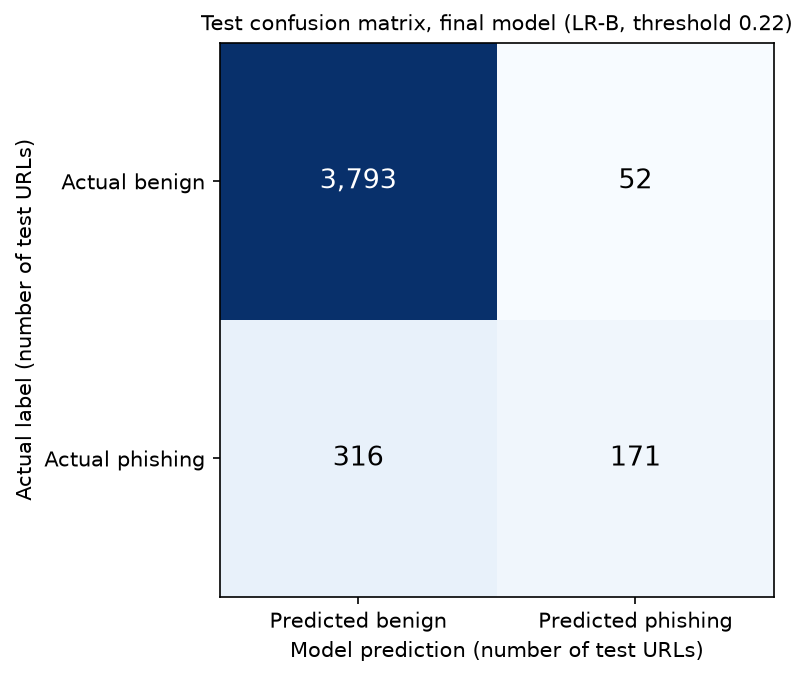

In [21]:
# The official test file is opened only here, after every modelling choice above is fixed.
test = pd.read_csv("data/splits/url_test.csv", dtype=str, keep_default_na=False,
                   usecols=["split", "tier", "label", "url", "collected_at"])
test = test[test["tier"].isin(["gold", "silver"])].reset_index(drop=True).copy()
assert len(test) == 4332 and set(test["split"]) == {"test"}
test["y"] = (test["label"] == "phishing").astype(int)
yt = test["y"].values
p_test = final_url.predict_proba(test[["url"]])[:, 1]
test_feat = uf.features_frame(test["url"])
base_maj = summarize_pred(yt, np.zeros(len(yt), bool))
base_has = summarize_pred(yt, test_feat["has_at"].values.astype(bool))
final_test = summarize_pred(yt, p_test >= FINAL_THR, p_test)

def wilson(k, nn, z=1.959964):
    p = k / nn; den = 1 + z * z / nn
    c = (p + z * z / (2 * nn)) / den; h = z * math.sqrt(p * (1 - p) / nn + z * z / (4 * nn * nn)) / den
    return p, max(c - h, 0.0), min(c + h, 1.0)

def cell(v):
    return round(v, 3) if isinstance(v, float) and not math.isnan(v) else v

rows = [["Final model (" + SELECTED + ")", *[final_test[k] for k in ["TP", "FP", "FN", "TN"]],
         cell(final_test["precision"]), cell(final_test["recall"]), cell(final_test["FPR"]),
         round(final_test["cost_per_1000"], 1), cell(final_test["AUC"])],
        ["Majority class (always benign)", *[base_maj[k] for k in ["TP", "FP", "FN", "TN"]],
         np.nan, cell(base_maj["recall"]), cell(base_maj["FPR"]), round(base_maj["cost_per_1000"], 1), np.nan],
        ["Heuristic: has_at = 1", *[base_has[k] for k in ["TP", "FP", "FN", "TN"]],
         cell(base_has["precision"]) if base_has["TP"] + base_has["FP"] else np.nan,
         cell(base_has["recall"]), cell(base_has["FPR"]), round(base_has["cost_per_1000"], 1), np.nan]]
test_table = pd.DataFrame(rows, columns=["model", "TP", "FP", "FN", "TN", "precision", "recall", "FPR",
                                         "cost per 1,000 URLs (EUR)", "AUC"])
display(test_table)
p_rec, lo, hi = wilson(final_test["TP"], final_test["TP"] + final_test["FN"])
print(f"Test recall {p_rec:.3f}, Wilson 95% CI [{lo:.3f}, {hi:.3f}]; test prevalence {100 * yt.mean():.1f}%")

cm = np.array([[final_test["TN"], final_test["FP"]], [final_test["FN"], final_test["TP"]]])
fig = go.Figure(go.Heatmap(z=cm, x=["Predicted benign", "Predicted phishing"], y=["Actual benign", "Actual phishing"],
                           text=cm, texttemplate="%{text}", colorscale="Blues", showscale=False))
fig.update_layout(title=f"Test confusion matrix, final model ({SELECTED}, threshold {FINAL_THR:.2f})",
                  xaxis_title="Model prediction (number of URLs)", yaxis_title="Actual label (number of URLs)")
fig.write_html("figures/fig_08_1_test_confusion.html", include_plotlyjs="cdn")
fig

fig_m, ax = plt.subplots(figsize=(5.8, 4.8))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{int(v):,}", ha="center", va="center", fontsize=13,
            color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["Predicted benign", "Predicted phishing"])
ax.set_yticks([0, 1], ["Actual benign", "Actual phishing"])
ax.set_xlabel("Model prediction (number of test URLs)")
ax.set_ylabel("Actual label (number of test URLs)")
ax.set_title(f"Test confusion matrix, final model ({SELECTED}, threshold {FINAL_THR:.2f})", fontsize=10)
save_static(fig_m, "fig_08_1_test_confusion.png")

**Post-evaluation diagnostic (second reading of test labels).** It changes no threshold, feature or model.

In [22]:
dev_ph = dev[dev["y"] == 1]
test_ph = test[test["y"] == 1].assign(dt=lambda d: pd.to_datetime(d["collected_at"].str.strip(), errors="coerce",
                                                                  dayfirst=True, format="mixed"))
yr = pd.DataFrame({
    "development phishing %": (100 * dev_ph["dt"].dt.year.value_counts(normalize=True)).round(1),
    "test phishing %": (100 * test_ph["dt"].dt.year.value_counts(normalize=True)).round(1),
    "development phishing (n)": dev_ph["dt"].dt.year.value_counts(),
    "test phishing (n)": test_ph["dt"].dt.year.value_counts()}).sort_index()
print("First-seen year of phishing URLs:")
display(yr.fillna(0))

feat_test = uf.features_frame(test["url"])
test_p = test.loc[test["y"] == 1].index
test_ph = test_ph.assign(f_url_len=feat_test.loc[test_p, "url_len"].values,
                         f_num_dots=feat_test.loc[test_p, "num_dots"].values,
                         f_num_subdomains=feat_test.loc[test_p, "num_subdomains"].values,
                         f_tld=feat_test.loc[test_p, "tld"].values)
dev_oof, dev_thr = R_PRED[SELECTED]
comp = pd.DataFrame({
    "development (phishing rows)": [dev_ph["f_url_len"].median(), dev_ph["f_num_dots"].median(),
                                    dev_ph["f_num_subdomains"].median(), 100 * (dev_ph["f_tld"] == "vn").mean()],
    "test (phishing rows)": [test_ph["f_url_len"].median(), test_ph["f_num_dots"].median(),
                             test_ph["f_num_subdomains"].median(), 100 * (test_ph["f_tld"] == "vn").mean()]},
    index=["median url_len", "median num_dots", "median num_subdomains", "% with TLD .vn"]).round(2)
print("Distribution of phishing URLs, development versus test:")
display(comp)

ycal = pd.DataFrame({
    "observed prevalence %": [100 * dev["y"].mean(), 100 * yt.mean()],
    "mean predicted probability %": [100 * dev_oof.mean(), 100 * p_test.mean()],
    "share flagged at the final threshold %": [100 * (dev_oof >= dev_thr).mean(), 100 * (p_test >= FINAL_THR).mean()]},
    index=["development (random reference OOF)", "test"]).round(2)
print("Calibration in the large and threshold transfer:")
display(ycal)

dev_ph_rec = dev.loc[dev["y"] == 1].assign(yr=lambda d: d["dt"].dt.year.clip(upper=2024),
                                            pred=lambda d: (dev_oof >= dev_thr)[d.index])
rec_dev = dev_ph_rec.groupby("yr")["pred"].mean()
test_ph_rec = test_ph.assign(yr=lambda d: d["dt"].dt.year.clip(lower=2023),
                             pred=p_test[(test["y"] == 1).values] >= FINAL_THR)
rec_test = test_ph_rec.groupby("yr")["pred"].mean()
recall_by_year = pd.DataFrame({"recall, development (random reference OOF)": rec_dev.round(3),
                               "recall, test (post hoc)": rec_test.round(3)})
print("Recall by first-seen year (development: random reference OOF; test: post hoc):")
display(recall_by_year)
vn_test = (feat_test.loc[test_p, "tld"] == "vn").values
hit_test = p_test[(test["y"] == 1).values] >= FINAL_THR
print(f"Post hoc, test recall by TLD group: .vn {hit_test[vn_test].mean():.3f} (n = {int(vn_test.sum())} phishing); "
      f"other TLDs {hit_test[~vn_test].mean():.3f} (n = {int((~vn_test).sum())} phishing)")

First-seen year of phishing URLs:


,development phishing %,test phishing %,development phishing (n),test phishing (n)
dt,,,,
2020,18.5,0.0,389.0,0.0
2021,54.1,0.0,1136.0,0.0
2022,26.7,0.0,560.0,0.0
2023,0.5,23.4,11.0,114.0
2024,0.2,68.6,4.0,334.0
2025,0.0,8.0,0.0,39.0


Distribution of phishing URLs, development versus test:


,development (phishing rows),test (phishing rows)
median url_len,13.00,16.0
median num_dots,1.00,1.0
median num_subdomains,0.00,0.0
% with TLD .vn,2.81,7.6


Calibration in the large and threshold transfer:


,observed prevalence %,mean predicted probability %,share flagged at the final threshold %
development (random reference OOF),14.32,14.32,10.60
test,11.24,7.98,5.15


Recall by first-seen year (development: random reference OOF; test: post hoc):


,"recall, development (random reference OOF)","recall, test (post hoc)"
yr,,
2020,0.617,NaN
2021,0.482,NaN
2022,0.773,NaN
2023,0.364,0.272
2024,1.000,0.380
2025,NaN,0.333


Post hoc, test recall by TLD group: .vn 0.000 (n = 37 phishing); other TLDs 0.380 (n = 450 phishing)


**What this means for the stakeholder.** Against doing nothing, test cost is 30 % lower (7,852 against 11,242 EUR per 1,000 URLs). Recall is 35 %, against 73 % in primary validation (threshold 0.25), so plan on finding under half of phishing URLs.

## 9. Interpretation

**Permutation importance** (Altmann et al., 2010) measures the rise in Brier score (Brier, 1950) and the fall in ROC AUC when an input is shuffled. It uses the five held-out random folds. The **individual predictions** below are three fold-0 URLs, shown with features only (threshold 0.31): the true positive has five dots and scores 1.000; the false negative has two dots, a `.vn` domain and scores 0.001; the false positive has one dot, a `.top` domain and scores 0.965.

Permutation importance on held-out folds (positive = the model gets worse when the input is shuffled):


,Brier score rise: mean,Brier score rise: SD over folds,ROC AUC drop: mean,ROC AUC drop: SD over folds
num_dots,0.17489,0.03380,0.29469,0.03594
num_subdomains,0.16398,0.01748,0.19368,0.02481
tld,0.07423,0.00697,0.24648,0.02465
url_len,0.00141,0.00061,0.00394,0.00258
has_at,0.00001,0.00001,0.00008,0.00017


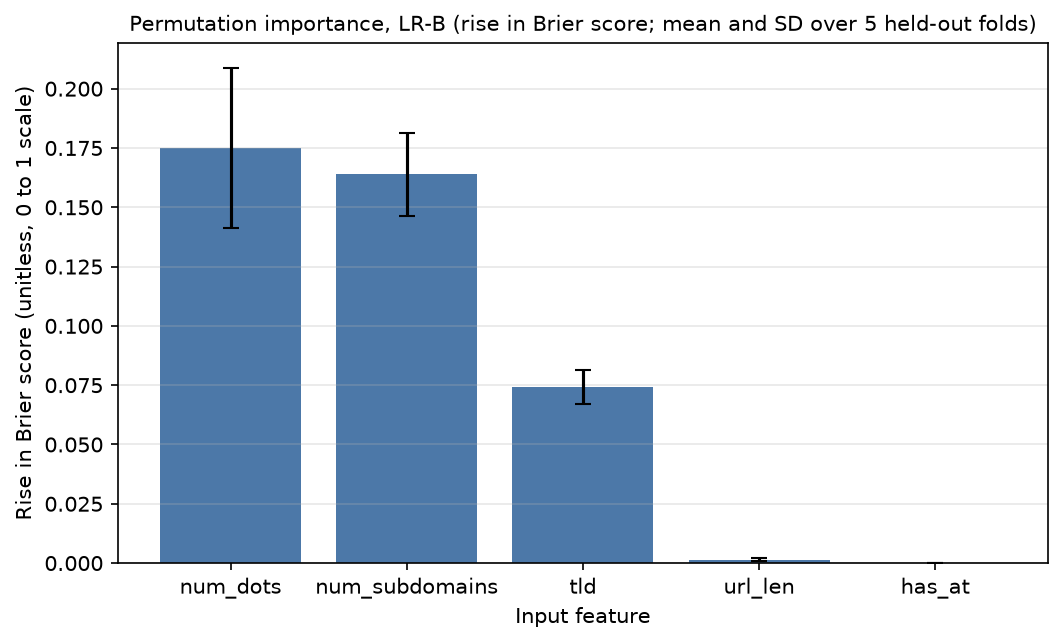

In [23]:
cols_sel = INPUTS_B if SEL_TLD else INPUTS_A
rows_imp = {"Brier score rise": [], "ROC AUC drop": []}
for mdl, va in zip(R_FOLD_MODELS[SELECTED][0], R_FOLD_MODELS[SELECTED][1]):
    for label, scorer in [("Brier score rise", "neg_brier_score"), ("ROC AUC drop", "roc_auc")]:
        r = permutation_importance(mdl, FX.loc[va, cols_sel], y[va], scoring=scorer, n_repeats=10, random_state=SEED)
        rows_imp[label].append(r.importances_mean)
imp_summary = pd.DataFrame(index=cols_sel)
for label in rows_imp:
    arr = np.vstack(rows_imp[label])
    imp_summary[f"{label}: mean"] = arr.mean(axis=0)
    imp_summary[f"{label}: SD over folds"] = arr.std(axis=0, ddof=1)
imp_summary = imp_summary.sort_values("Brier score rise: mean", ascending=False).round(5)
print("Permutation importance on held-out folds (positive = the model gets worse when the input is shuffled):")
display(imp_summary)
fig = px.bar(imp_summary.reset_index(names="variable"), x="variable", y="Brier score rise: mean",
             error_y="Brier score rise: SD over folds",
             title=f"Permutation importance, {SELECTED} (rise in Brier score; mean and SD over 5 held-out folds)",
             labels={"variable": "Input feature", "Brier score rise: mean": "Rise in Brier score (unitless, 0 to 1 scale)"})
fig.write_html("figures/fig_09_1_permutation_importance.html", include_plotlyjs="cdn")
fig

fig_m, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(imp_summary.index, imp_summary["Brier score rise: mean"].values,
       yerr=imp_summary["Brier score rise: SD over folds"].values, capsize=4, color="#4C78A8")
ax.set_title(f"Permutation importance, {SELECTED} (rise in Brier score; mean and SD over 5 held-out folds)", fontsize=10)
ax.set_xlabel("Input feature")
ax.set_ylabel("Rise in Brier score (unitless, 0 to 1 scale)")
ax.grid(axis="y", alpha=0.3)
save_static(fig_m, "fig_09_1_permutation_importance.png")

In [24]:
# Three individual predictions from fold 0 of the random reference (features only, no URLs are printed)
va0 = R_FOLD_MODELS[SELECTED][1][0]
p0 = R_PRED[SELECTED][0][va0]; t0 = R_PRED[SELECTED][1][va0]; y0 = y[va0]
f0 = FX.loc[va0].reset_index(drop=True)
cases = {}
idx_tp = np.where((y0 == 1) & (p0 >= t0))[0]
idx_fn = np.where((y0 == 1) & (p0 < t0))[0]
idx_fp = np.where((y0 == 0) & (p0 >= t0))[0]
if len(idx_tp): cases["true positive (highest score)"] = idx_tp[np.argmax(p0[idx_tp])]
if len(idx_fn): cases["false negative (lowest score)"] = idx_fn[np.argmin(p0[idx_fn])]
if len(idx_fp): cases["false positive (highest score)"] = idx_fp[np.argmax(p0[idx_fp])]
rows = [[k, round(float(p0[j]), 3), round(float(t0[j]), 2), *[f0.loc[j, c] for c in cols_sel]] for k, j in cases.items()]
display(pd.DataFrame(rows, columns=["case", "probability", "threshold", *cols_sel]))

,case,probability,threshold,url_len,num_dots,num_subdomains,has_at,tld
0,true positive (highest score),1.000,0.31,19,5,4,0,bar
1,false negative (lowest score),0.001,0.31,13,2,0,0,vn
2,false positive (highest score),0.965,0.31,24,1,0,0,top


**What this means for the stakeholder.** Decisions depend mainly on dots, subdomains and the top-level domain; URL length and `has_at` add little. H2 and H3 are only partly reflected. The counts are easy for attackers to change, so the importances describe the score, not why a URL is dangerous.

## 10. Fairness, ethics and risks

**Groups.** `.vn` and other top-level domains are compared with Wilson 95 % intervals (Wilson, 1927); small groups are weak evidence. **Label quality.** The publisher's audit (Nguyen Vu, 2026, Section 4) judged 12 of 99 resolvable phishing labels legitimate (12.1 %) and 2 of 50 benign labels abusive (4.0 %). These rates describe that sample only. **Privacy.** The publisher states that personal data are redacted (Nguyen Vu, 2026); the GDPR (European Union, 2016) would apply to any stored URL.

,evaluation,group,URLs,phishing,FPR,FPR 95% CI,recall,recall 95% CI,"cost per 1,000 URLs (EUR)"
0,random reference (5 folds),.vn TLD,7243,59,0.0024,"[0.0015, 0.0038]",0.000,"[0.000, 0.061]",885.0
1,random reference (5 folds),other TLDs,7422,2041,0.0572,"[0.0513, 0.0638]",0.602,"[0.581, 0.623]",13013.3
2,primary temporal validation,.vn TLD,2470,7,0.0000,"[0.0000, 0.0016]",0.000,"[0.000, 0.354]",283.4
3,primary temporal validation,other TLDs,2220,567,0.1010,"[0.0874, 0.1165]",0.735,"[0.698, 0.770]",9952.7


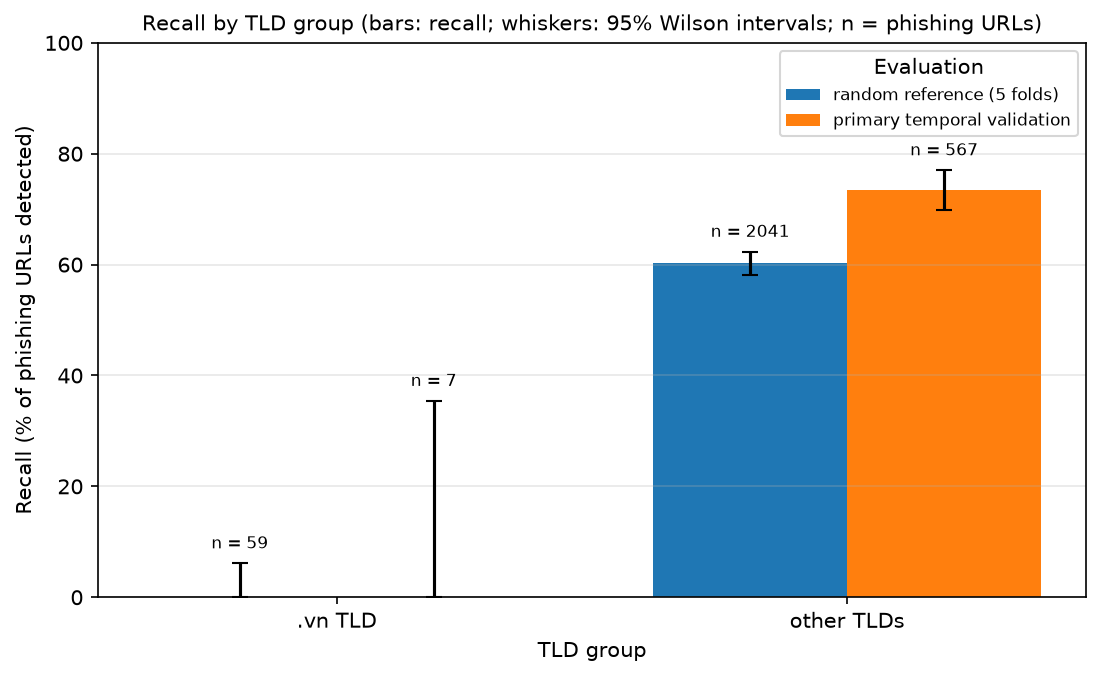

In [25]:
def group_table(yy, pred, mask_vn, name):
    rows = []
    for gname, m in [(".vn TLD", mask_vn), ("other TLDs", ~mask_vn)]:
        yy_g, pr_g = yy[m], pred[m]
        s = summarize_pred(yy_g, pr_g)
        p_fpr, lo_f, hi_f = wilson(s["FP"], s["FP"] + s["TN"])
        if s["TP"] + s["FN"]:
            p_rec, lo_r, hi_r = wilson(s["TP"], s["TP"] + s["FN"])
        else:
            p_rec, lo_r, hi_r = np.nan, np.nan, np.nan
        rows.append([name, gname, int(m.sum()), int(yy_g.sum()), round(p_fpr, 4), f"[{lo_f:.4f}, {hi_f:.4f}]",
                     round(p_rec, 3), f"[{lo_r:.3f}, {hi_r:.3f}]", round(s["cost_per_1000"], 1)])
    return rows

is_vn = (dev["f_tld"] == "vn").values
pr_R, thr_R = R_PRED[SELECTED]
pred_R = pr_R >= thr_R
rows = group_table(y, pred_R, is_vn, "random reference (5 folds)")
is_val_p, p_primary, thr_primary = PRED[(PRIMARY, SELECTED)]
rows += group_table(y[is_val_p], p_primary >= thr_primary, is_vn[is_val_p], "primary temporal validation")
fair = pd.DataFrame(rows, columns=["evaluation", "group", "URLs", "phishing", "FPR", "FPR 95% CI",
                                   "recall", "recall 95% CI", "cost per 1,000 URLs (EUR)"])
display(fair)
fair_plot = fair.assign(recall_pct=100 * fair["recall"])
fig = px.bar(fair_plot, x="group", y="recall_pct", color="evaluation", barmode="group",
             title="Recall by TLD group in both evaluations (95% Wilson intervals in the table above)",
             labels={"group": "TLD group", "recall_pct": "Recall (% of phishing URLs detected)", "evaluation": "Evaluation"})
fig.write_html("figures/fig_10_1_recall_by_tld_group.html", include_plotlyjs="cdn")
fig

groups_tld = list(dict.fromkeys(fair["group"]))
evals_tld = list(dict.fromkeys(fair["evaluation"]))
fig_m, ax = plt.subplots(figsize=(8.5, 4.8))
x_pos = np.arange(len(groups_tld)); w = 0.38
for i, ev in enumerate(evals_tld):
    sub = fair[fair["evaluation"] == ev].set_index("group").loc[groups_tld]
    r = 100 * sub["recall"].values
    ci = [literal_eval(s) for s in sub["recall 95% CI"]]
    lo = 100 * np.array([c[0] for c in ci]); hi = 100 * np.array([c[1] for c in ci])
    ax.bar(x_pos + (i - 0.5) * w, r, w, label=ev, yerr=[r - lo, hi - r], capsize=4)
    for xv, hv, nv in zip(x_pos + (i - 0.5) * w, hi, sub["phishing"].values):
        ax.text(xv, hv + 2, f"n = {int(nv)}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x_pos, groups_tld)
ax.set_ylim(0, 100)
ax.set_xlabel("TLD group")
ax.set_ylabel("Recall (% of phishing URLs detected)")
ax.set_title("Recall by TLD group (bars: recall; whiskers: 95% Wilson intervals; n = phishing URLs)", fontsize=10)
ax.legend(title="Evaluation", fontsize=8)
ax.grid(axis="y", alpha=0.3)
save_static(fig_m, "fig_10_1_recall_by_tld_group.png")

In [26]:
fp_mask = pred_R & (y == 0)
fp_src = dev.loc[fp_mask].groupby("source").size().rename("false positives (random reference)").to_frame()
print(f"False positives in the random reference: {int(fp_mask.sum())}; "
      f"in .gov.vn domains: {int(dev.loc[fp_mask, 'grp'].str.endswith('.gov.vn').sum())}")
display(fp_src)

False positives in the random reference: 325; in .gov.vn domains: 1


,false positives (random reference)
source,
tinnhiem_org,29
tinnhiem_web,30
tranco,266


**Risks and who bears them.**

| Error | Who is affected | Mitigation |
|---|---|---|
| False positive | Legitimate, mostly popular international sites | Human review only |
| False negative | Users and the organisation | Keep existing controls; monitor recall |
| `.vn` or out-of-region traffic | Vietnamese users and sites | Not without new labelled data |
| Mislabelled positives | Anyone trusting precision | Treat precision as optimistic (12 % audit error) |
| Privacy | People whose URLs contain personal data | Store no URLs; GDPR review first |

**What this means for the stakeholder.** No `.vn` phishing URL was caught in the random folds (59), temporal validation (7) or the test set (37). Most false alarms fall on popular international sites (266 of 325).

## 11. Recommendation

**Decision.** Use the score to order URLs for human review, not to block them.

**Expected improvement.** Against doing nothing, cost falls from 11,242 to 7,852 EUR per 1,000 URLs (illustrative prices). Per 1,000 URLs, 39 phishing URLs reach an analyst first, 12 benign URLs are reviewed unnecessarily and 73 are missed. The improvement over the current rule cannot be quantified: that rule is not documented.

**Do not trust it for.** `.vn` traffic; other regions or languages; unfamiliar URLs; shifts in the phishing mix; any euro figure before the illustrative costs are replaced.

**Information needed.** A written description of the current rule and its results. **Next steps.** Retrain on new audited labels, track recall by year and TLD, and recalibrate. Block 4 adds deployment and monitoring.

**What this means for the stakeholder.** The model is a queue for human review, not an automatic filter; re-measure it on each new labelled batch.

## 12. Saving the model

The pipeline runs from raw URL to calibrated probability and is saved with joblib (joblib developers, 2026) to `project/model.joblib`. It imports `url_features.py`. `model_config.json` records the threshold and SHA-256 fingerprints of the model, feature code and Public Suffix List. The file is reloaded below and checked by `test_saved_model.py` in a fresh process. Library versions, including pandas (pandas development team, 2026) and NumPy (NumPy developers, 2026), are printed.

In [27]:
MODEL_PATH = Path("model.joblib")
joblib.dump(final_url, MODEL_PATH)
model_sha = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
reloaded = joblib.load(MODEL_PATH)
demo = pd.DataFrame({"url": ["http://demo-login.example/account", "https://www.example.org/help"]})  # fictitious
p_mem = final_url.predict_proba(demo)[:, 1]
p_load = reloaded.predict_proba(demo)[:, 1]
assert np.allclose(p_mem, p_load, atol=1e-12), "Reloaded model differs from the in-memory model"
assert ((p_load >= 0) & (p_load <= 1)).all()
psl_sha = hashlib.sha256(Path("psl/public_suffix_list.dat").read_bytes()).hexdigest()
assert psl_sha == uf.PSL_SHA256
config = {
    "pipeline_version": "entrega2-v3",
    "configuration": SELECTED,
    "calibration": FINAL_METHOD,
    "hyperparameters": {k: float(v) for k, v in FINAL_PARAMS.items()},
    "threshold": round(FINAL_THR, 2),
    "threshold_rule": "minimum cost on nested out-of-fold predictions of all development rows (hyperparameters chosen inside each fold's training part)",
    "costs_illustrative_EUR": COST,
    "seed": SEED,
    "inputs": final_cols,
    "primary_validation": {"protocol": PRIMARY, "cutoff": str(CUTOFF_PRIMARY.date())},
    "model_sha256": model_sha,
    "url_features_sha256": hashlib.sha256(Path("url_features.py").read_bytes()).hexdigest(),
    "psl_version": uf.PSL_VERSION,
    "psl_commit": uf.PSL_COMMIT,
    "psl_sha256": psl_sha,
    "demo_expected": {u: round(float(p), 6) for u, p in zip(demo["url"], p_load)},
}
Path("model_config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved model.joblib and model_config.json | model sha256:", model_sha[:16], "...")
display(pd.DataFrame({"url": demo["url"], "probability": p_load.round(3), "flag for review": p_load >= FINAL_THR}))

Saved model.joblib and model_config.json | model sha256: ae32a3385a5226fb ...


,url,probability,flag for review
0,http://demo-login.example/account,0.153,False
1,https://www.example.org/help,0.484,True


In [28]:
import importlib.metadata as md_
import sys as _sys
print("Library versions:")
for mod in ["scikit-learn", "pandas", "numpy", "scipy", "joblib", "plotly", "publicsuffixlist"]:
    print(f"  {mod} {md_.version(mod)}")
print(f"  python {_sys.version.split()[0]}")
print(f"Total run time: {time.time() - T0:.0f} s")

Library versions:
  scikit-learn 1.9.1
  pandas 3.0.5
  numpy 2.5.3
  scipy 1.18.1
  joblib 1.6.0
  plotly 7.1.0
  publicsuffixlist 1.1.2.20261112
  python 3.13.18
Total run time: 276 s


**What this means for the stakeholder.** The saved file scores a raw URL string directly. Stored fingerprints detect any change to the model, feature code or Public Suffix List.

## 13. References

Altmann, A., Toloşi, L., Sander, O., & Lengauer, T. (2010). Permutation importance: A corrected feature importance measure. *Bioinformatics, 26*(10), 1340–1347. https://doi.org/10.1093/bioinformatics/btq134

Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review, 78*(1), 1–3.

European Union. (2016). *Regulation (EU) 2016/679 (General Data Protection Regulation)*. Official Journal of the European Union, L 119, 1–88. https://eur-lex.europa.eu/eli/reg/2016/679/oj

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451

Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied logistic regression* (3rd ed.). Wiley.

joblib developers. (2026). *joblib* (Version 1.6.0) [Computer software]. https://pypi.org/project/joblib/1.6.0/

Kruskal, W. H., & Wallis, W. A. (1952). Use of ranks in one-criterion variance analysis. *Journal of the American Statistical Association, 47*(260), 583–621. https://doi.org/10.2307/2280779

Le Pochat, V., Van Goethem, T., Tajalizadehkhoob, S., Korczyński, M., & Joosen, W. (2019). Tranco: A research-oriented top sites ranking hardened against manipulation. In *Proceedings of the 26th Network and Distributed System Security Symposium (NDSS 2019)*. https://www.ndss-symposium.org/ndss-paper/tranco-a-research-oriented-top-sites-ranking-hardened-against-manipulation/

Mann, H. B., & Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. *The Annals of Mathematical Statistics, 18*(1), 50–60. https://doi.org/10.1214/aoms/1177730491

Matplotlib Development Team. (2026). *matplotlib* (Version 3.11.2) [Computer software]. https://pypi.org/project/matplotlib/3.11.2/

Niculescu-Mizil, A., & Caruana, R. (2005). Predicting good probabilities with supervised learning. In *Proceedings of the 22nd International Conference on Machine Learning* (pp. 625–632).

NumPy developers. (2026). *numpy* (Version 2.5.3) [Computer software]. https://pypi.org/project/numpy/2.5.3/

pandas development team. (2026). *pandas* (Version 3.0.5) [Computer software]. https://pypi.org/project/pandas/3.0.5/

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

Plotly Technologies Inc. (2026). *plotly* (Version 7.1.0) [Computer software]. https://pypi.org/project/plotly/7.1.0/

publicsuffixlist. (2026). *publicsuffixlist* (Version 1.1.2.20261112) [Computer software]. https://pypi.org/project/publicsuffixlist/1.1.2.20261112/

Public Suffix List. (2026). *Public Suffix List* (Version 2026-11-11_17-18-20_UTC, commit 529030148729033bc6c30dbb05753b805a7d2155) [Data set]. https://publicsuffix.org/

SciPy developers. (2026). *SciPy* (Version 1.18.1) [Computer software]. https://pypi.org/project/scipy/1.18.1/

Nguyen Vu, T. (2026). *PhishVN: A time-stamped Vietnamese URL phishing dataset with impersonation-scenario labels and confidence tiers* (Version 4) [Data set]. Mendeley Data. https://doi.org/10.17632/b97hxbxtpd.4

Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212. https://doi.org/10.2307/2276774

**What this means for the stakeholder.** Every figure depends on PhishVN version 4 and on the software versions listed. The publisher's audit found 12 of 99 sampled phishing labels legitimate, so treat precision as optimistic, as Section 10 notes. Not all references could be checked against their original registries.
